# 01 — Exploratory Data Analysis: WiDS 2024 Challenge #1

**Course:** Data Mining and Applications, HCMUS. **Stage:** read-only exploratory analysis.

This notebook investigates data structure, semantic roles, missingness, distributions, and
associations to formulate preprocessing hypotheses, without validating a chosen method. Outputs are computed from the local official
training CSV. They are descriptive observations about this training sample, not validated
clinical claims, causal effects, or estimates of predictive performance.

## 1. Problem definition, source, and limitations

- **Official source:** [WiDS Datathon 2024 — Challenge #1, Data](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data)
  and [competition rules](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/rules).
- **Outcome:** supplied binary column `DiagPeriodL90D`; **identifier:** `patient_id`.
  The exact clinical endpoint, threshold convention, positive-label polarity, and cohort
  eligibility are **unverified here**. Classes are called **0 and 1**, not “early” or “delayed”.
  The Kaggle page was consulted, but an authoritative field dictionary could not be retrieved
  as readable text during authoring. No disease-code meanings or measurement units are invented.
- **Input contract:** `data/raw/training.csv`, expected 12,906 rows and 83 columns.
  `sample_submission.csv` is a submission template and is never read. No test CSV is read.
- **Provisional prediction question:** could information available at a baseline breast-cancer
  diagnosis predict this supplied outcome? This is a **working temporal scenario**, not a
  verified competition protocol. The actual prediction time must be confirmed before modeling.
- **Scope and limitations:** this is a selected observational training sample. Patient uniqueness
  does not establish independent sampling; patients share geographic context. Feature dates,
  collection processes, units, and data provenance within the cohort are not supplied in this CSV.
  Associations may reflect selection, recording, geographic clustering, and confounding.
  Exploring labels on the full training sample is hypothesis generation; later model evaluation
  needs a declared validation design. Every row and its label has already contributed to EDA;
  a later split of this same file cannot be described as a completely untouched test set.

**Read-only contract:** no rows or columns are removed from the loaded training frame; no
imputation, scaling, encoding, outlier treatment, feature selection, or model fitting is performed.
Selections and group summaries below are temporary diagnostics. Only this notebook's outputs are
saved. The final cell checks both the CSV checksum and the in-memory frame fingerprint.

**Official-rubric audit (25 October 2026):** the complete official assignment page was retrieved
with HTTP 200 and audited before these corrections. Required EDA includes all-feature normality
tests, full Pearson/Spearman correlation coverage, `missingno.matrix`, and Little's MCAR test.
See the repository's `RUBRIC_AUDIT.md` for the before/final matrices, future requirements, grading
ambiguities, and criteria that remain PARTIAL or NOT VERIFIED. A numerical calculation is not
by itself proof of statistical assumptions or full rubric compliance.


In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from importlib.metadata import version
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as msno
import warnings
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

# Works from the repository root, book/, or book/tabular/; no machine-specific paths.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "myst.yml").is_file() and (p / "src/validate_dataset.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside the data-mining-preprocessing repository.")
if Path(sys.prefix) != ROOT / ".venv":
    raise RuntimeError("Select the project's .venv kernel (hcmus-wids), then restart and run all.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / "data/raw/training.csv"
TARGET, ID = "DiagPeriodL90D", "patient_id"
EXPECTED_SHAPE = (12906, 83)  # Input contract; edit or set None when adapting to another dataset.
RANDOM_STATE = 42
NEAR_CONSTANT_SHARE = 0.95
RARE_SHARE = 0.01
MIN_CORRELATION_N = 100
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140})
pd.set_option("display.max_columns", 14)
print(f"Python {platform.python_version()}; verified kernel: .venv/bin/python")
display(pd.DataFrame({
    "package": ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels"],
    "version": [version(p) for p in ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels"]],
}))

# Reuse: update DATA_PATH, TARGET, ID, EXPECTED_SHAPE, then review semantic/plot/test lists below.
# Numerical storage alone never establishes that a new feature is a continuous measurement.
ALPHA = 0.05
STRONG_CORRELATION = 0.9


Python 3.13.3; verified kernel: .venv/bin/python


,package,version
0,numpy,2.5.4
1,pandas,3.1.0
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scipy,1.18.1
5,statsmodels,0.15.0


## 2. Loading, schema, integrity, and class balance

**Question:** is this the expected labeled training file, and are IDs and labels usable for
exploration? Read exactly the training path and verify the supplied shape and column contract.
Pandas' default NA recognition is recorded explicitly; a later lexical read checks candidate
sentinel tokens without replacing them. No patient rows or IDs are displayed in publication.

**ZIP parsing audit:** compare the literal `patient_zip3` tokens in this CSV with pandas' default
inference. Then load that identifier explicitly as `string`, preserving any leading zeros in
future files without inventing zero-padding. The CSV itself cannot establish whether a code
was altered upstream. The literal `999` is retained; its geographic validity or possible
sentinel meaning needs a dictionary, not a numeric rule.

Input preparation: existing training.csv; no download or replacement performed


,ZIP parsing audit
default pandas ZIP dtype,int64
chosen ZIP storage dtype,string
ZIP semantic role,geographic code / nominal category
literal ZIP rows,12906
distinct literal ZIP codes,739
leading-zero rows in this CSV,0
tokens not exactly three digits,0
"literal 999 rows, retained",1


,observed
rows,12906
columns,83
feature_columns,81
missing_IDs,0
duplicate_nonmissing_IDs_after_first,0
duplicate_rows_after_first,0
missing_labels,0
deep_memory_MiB,14.967


Input SHA-256: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9


,patients,share_pct
class,,
0,4846,37.548
1,8060,62.452


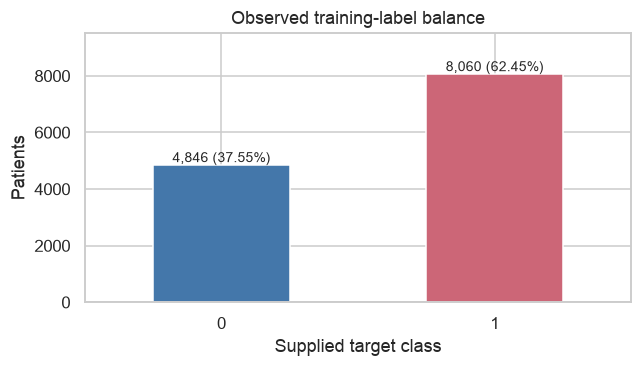

**Observed:** class 1 accounts for **62.45%** and class 0 for **37.55%**. This is unequal class representation, not evidence that resampling is needed. Later evaluation should compare suitable metrics against a majority-class reference; no classifier or resampling is run here. Unique IDs do not rule out repeat patients under different IDs.

In [2]:
# Optional cold-start preparation: never replace an existing training CSV.
# Credentials/rules acceptance must be configured by the user outside this notebook.
DOWNLOAD_IF_MISSING = False
download_performed = False
if not DATA_PATH.is_file() and DOWNLOAD_IF_MISSING:
    import subprocess
    import zipfile
    import shutil
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([str(ROOT / ".venv/bin/kaggle"), "competitions", "download",
                    "widsdatathon2024-challenge1", "-p", str(DATA_PATH.parent)], check=True)
    archive_path = DATA_PATH.parent / "widsdatathon2024-challenge1.zip"
    with zipfile.ZipFile(archive_path) as archive:
        candidates = [name for name in archive.namelist() if Path(name).name.casefold() == "training.csv"]
        if len(candidates) != 1:
            raise ValueError("Official archive does not contain exactly one training.csv")
        with archive.open(candidates[0]) as source, DATA_PATH.open("xb") as destination:
            shutil.copyfileobj(source, destination)
    download_performed = True
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download the official training.csv after Kaggle authentication/rules acceptance; see README.")
print("Input preparation:", "downloaded the official training file" if download_performed
      else "existing training.csv; no download or replacement performed")
raw_sha256_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
zip_tokens = pd.read_csv(
    DATA_PATH, usecols=["patient_zip3"], dtype="string", keep_default_na=False
)["patient_zip3"]
default_zip_dtype = str(pd.read_csv(DATA_PATH, usecols=["patient_zip3"]).patient_zip3.dtype)
zip_leading_zero_n = int(zip_tokens.str.startswith("0").sum())
zip_literal_999_n = int(zip_tokens.eq("999").sum())

# Set storage type at read time; do not repair, pad, encode, or overwrite geographic codes.
df = pd.read_csv(DATA_PATH, dtype={"patient_zip3": "string"})
if EXPECTED_SHAPE is not None:
    assert df.shape == EXPECTED_SHAPE, f"Unexpected training shape: {df.shape}"
shape_before = df.shape
# Fail visibly if the selected parsing loses or changes any literal ZIP token.
assert df.patient_zip3.equals(zip_tokens), "ZIP parsing did not preserve all literal CSV tokens"
display(pd.Series({
    "default pandas ZIP dtype": default_zip_dtype,
    "chosen ZIP storage dtype": str(df.patient_zip3.dtype),
    "ZIP semantic role": "geographic code / nominal category",
    "literal ZIP rows": len(zip_tokens),
    "distinct literal ZIP codes": zip_tokens.nunique(),
    "leading-zero rows in this CSV": zip_leading_zero_n,
    "tokens not exactly three digits": int((~zip_tokens.str.fullmatch(r"[0-9]{3}")).sum()),
    "literal 999 rows, retained": zip_literal_999_n,
}, name="ZIP parsing audit").to_frame())
assert {ID, TARGET}.issubset(df.columns)
assert df.columns.is_unique
assert df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
frame_fingerprint_before = hashlib.sha256(
    pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()
).hexdigest()
dtypes_before = df.dtypes.copy()

feature_columns = [c for c in df.columns if c not in {ID, TARGET}]
integrity = pd.Series({
    "rows": len(df), "columns": len(df.columns), "feature_columns": len(feature_columns),
    "missing_IDs": int(df[ID].isna().sum()),
    "duplicate_nonmissing_IDs_after_first": int(df.loc[df[ID].notna(), ID].duplicated().sum()),
    "duplicate_rows_after_first": int(df.duplicated().sum()),
    "missing_labels": int(df[TARGET].isna().sum()),
    "deep_memory_MiB": round(df.memory_usage(index=True, deep=True).sum() / 1024**2, 3),
}, name="observed", dtype="object")
display(integrity.to_frame().round(3))
print("Input SHA-256:", raw_sha256_before)

balance = df[TARGET].value_counts().reindex([0, 1]).rename("patients").to_frame()
balance["share_pct"] = balance["patients"] / len(df) * 100
balance.index.name = "class"
display(balance.round(3))
ax = balance["patients"].plot.bar(color=["#4477AA", "#CC6677"], rot=0, figsize=(6, 3.5))
ax.set(title="Observed training-label balance", xlabel="Supplied target class", ylabel="Patients")
for bar, pct in zip(ax.patches, balance["share_pct"]):
    ax.annotate(f"{int(bar.get_height()):,} ({pct:.2f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, balance.patients.max() * 1.18)
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Observed:** class 1 accounts for **{balance.loc[1, 'share_pct']:.2f}%** "
    f"and class 0 for **{balance.loc[0, 'share_pct']:.2f}%**. "
    "This is unequal class representation, not evidence that resampling is needed. "
    "Later evaluation should compare suitable metrics against a majority-class reference; "
    "no classifier or resampling is run here. Unique IDs do not rule out repeat patients under different IDs."
))

## 3. Semantic feature audit and temporal leakage review

**Question:** what can each column represent, independently of its storage dtype?
The audit below covers every feature. Roles are **working interpretations of column names and
observed structure**, not a fabricated dictionary. In particular:

- `patient_zip3` is a geographic identifier with categories. The default reader inferred an
  integer, but the chosen loader stores it as `string`. The preceding literal-token audit
  establishes whether this particular CSV contains leading zeros; it does not verify upstream
  formatting. Neither storage type justifies means, distances, continuous correlations, or
  continuous-variable outlier rules. No padding, mapping, or geographic enrichment is performed.
- Diagnosis codes remain nominal codes. Their descriptions are recorded text, not independently
  verified code definitions. A code/description mapping check tests redundancy only.
- Treatment and diagnosis fields may be recorded at or after the outcome-defining process.
  All five such fields are excluded from target-association tests and continuous correlations
  as a conservative temporal precaution. They remain visible in structural/missingness audits.
- Age and BMI are candidate individual measurements, but their collection dates and units need
  confirmation. Area/context variables are not individual patient characteristics, even when
  attached to every row. None is approved for future prediction until its availability at the
  prediction time is verified.
- “Constant among observed values” differs from “constant across all rows”: a sparse column
  with one nonmissing value category can still have varying missingness. The 95% near-constant
  threshold is a diagnostic choice, not a deletion rule or course requirement.

In [3]:
clinical_review = {
    "breast_cancer_diagnosis_code", "breast_cancer_diagnosis_desc",
    "metastatic_cancer_diagnosis_code", "metastatic_first_novel_treatment",
    "metastatic_first_novel_treatment_type",
}
geographic_codes = {"patient_zip3", "patient_state", "Region", "Division"}
individual_categorical = {"patient_race", "payer_type", "patient_gender"}
individual_numeric = {"patient_age", "bmi"}
environment_columns = {"Ozone", "PM25", "N02"}  # Preserve the literal CSV name N02 (zero).

def semantic_role(column):
    if column in clinical_review:
        return "clinical code/text; temporal review"
    if column in geographic_codes:
        return "geographic category/code"
    if column in individual_categorical:
        return "individual nominal category"
    if column in individual_numeric:
        return "candidate individual numerical"
    if column in environment_columns:
        return "candidate contextual/environmental"
    if pd.api.types.is_numeric_dtype(df[column]):
        return "candidate contextual numerical"
    return "unclassified; review required"

records = []
for column in feature_columns:
    observed_counts = df[column].value_counts()
    records.append({
        "feature": column, "storage_dtype": str(df[column].dtype),
        "semantic_role": semantic_role(column),
        "missing_pct": df[column].isna().mean() * 100,
        "observed_unique": df[column].nunique(),
        "dominant_observed_pct": (observed_counts.iloc[0] / observed_counts.sum() * 100
                                  if len(observed_counts) else np.nan),
        "timing_status": ("high-risk/unverified" if column in clinical_review else "unverified"),
    })
audit = pd.DataFrame(records).set_index("feature")
continuous_columns = [
    c for c in feature_columns
    if c not in clinical_review | geographic_codes | individual_categorical
    and pd.api.types.is_numeric_dtype(df[c])
]
categorical_columns = [c for c in feature_columns if c not in continuous_columns]
assert len(audit) == len(feature_columns)
assert ID not in continuous_columns and TARGET not in continuous_columns
assert set(continuous_columns) | set(categorical_columns) == set(feature_columns)
assert "patient_zip3" in categorical_columns and "patient_zip3" not in continuous_columns
with pd.option_context("display.max_rows", 90):
    display(audit.round(3))
print(f"Semantic feature counts: {len(continuous_columns)} numerical candidates, "
      f"{len(categorical_columns)} categorical/code/text candidates; target and ID excluded.")
print("patient_zip3 categories:", df.patient_zip3.nunique())

single_observed = audit.loc[audit.observed_unique <= 1]
near_constant = audit.loc[
    (audit.observed_unique > 1) & (audit.dominant_observed_pct >= 100 * NEAR_CONSTANT_SHARE)
]
display(Markdown("**Single observed category / all-missing audit:**"))
display(single_observed[["observed_unique", "missing_pct", "dominant_observed_pct"]].round(3))
display(Markdown("**Near-constant features (excluding single-category columns):**"))
display(near_constant[["observed_unique", "dominant_observed_pct", "missing_pct"]].round(3))

code_to_description = df.groupby("breast_cancer_diagnosis_code")["breast_cancer_diagnosis_desc"].nunique()
description_to_code = df.groupby("breast_cancer_diagnosis_desc")["breast_cancer_diagnosis_code"].nunique()
print("Maximum descriptions per breast diagnosis code:", code_to_description.max())
print("Maximum breast diagnosis codes per description:", description_to_code.max())
print("An observed one-to-one mapping is a redundancy clue, not verification of code meanings.")

# Published tabular-selection requirements, checked on actual semantic features.
dataset_rubric = pd.Series({
    "rows_at_least_10000": len(df) >= 10000,
    "attributes_at_least_10_excluding_ID_target": len(feature_columns) >= 10,
    "has_numerical_and_categorical": bool(continuous_columns and categorical_columns),
    "at_least_one_feature_missing_5pct": bool((audit.missing_pct >= 5).any()),
}, name="rubric_met")
display(dataset_rubric.to_frame())
assert dataset_rubric.all()


,storage_dtype,semantic_role,missing_pct,observed_unique,dominant_observed_pct,timing_status
feature,,,,,,
patient_race,str,individual nominal category,49.473,5,55.022,unverified
payer_type,str,individual nominal category,13.970,3,54.328,unverified
patient_state,str,geographic category/code,0.395,50,18.965,unverified
patient_zip3,string,geographic category/code,0.000,739,1.852,unverified
patient_age,int64,candidate individual numerical,0.000,67,3.649,unverified
patient_gender,str,individual nominal category,0.000,1,100.000,unverified
bmi,float64,candidate individual numerical,69.464,1342,2.893,unverified
breast_cancer_diagnosis_code,str,clinical code/text; temporal review,0.000,50,15.357,high-risk/unverified
breast_cancer_diagnosis_desc,str,clinical code/text; temporal review,0.000,50,15.357,high-risk/unverified


Semantic feature counts: 69 numerical candidates, 12 categorical/code/text candidates; target and ID excluded.
patient_zip3 categories: 739


**Single observed category / all-missing audit:**

,observed_unique,missing_pct,dominant_observed_pct
feature,,,
patient_gender,1,0.000,100.0
metastatic_first_novel_treatment_type,1,99.814,100.0


**Near-constant features (excluding single-category columns):**

,observed_unique,dominant_observed_pct,missing_pct
feature,,,


Maximum descriptions per breast diagnosis code: 1
Maximum breast diagnosis codes per description: 1
An observed one-to-one mapping is a redundancy clue, not verification of code meanings.


,rubric_met
rows_at_least_10000,True
attributes_at_least_10_excluding_ID_target,True
has_numerical_and_categorical,True
at_least_one_feature_missing_5pct,True


## 4. Missing-value analysis

**Questions:** which features are sparsely recorded, which missingness patterns co-occur, and
which subpopulations are represented among observed values? Percentages use all training rows
unless a different denominator is shown. The diagnostic views below are temporary boolean
indicators and do not add encoded columns to the training frame.

The focused missingno matrix uses a deterministic sample of at most 250 rows (`random_state=42`), with anonymous
sample-position axes. The pattern table and indicator correlations use the **full training set**.
Only eight high-missingness columns enter the matrix/phi heatmap to keep them readable.
Long treatment-field labels are shortened for plots only; the audit retains their exact CSV names.

The missing-rate denominator, available-case group comparison, and missing-data mechanism are
three different quantities. Phi is undefined for a constant indicator; a rounded value of 1.00
is not, by itself, proof that two masks are identical. Counts below verify selected equal masks.
No missingness plot or p-value identifies MCAR, MAR, or MNAR.
A separate missingno overview below includes **all rows and all 81 features**. In missingno, white denotes missing values; the phi plot remains supplementary and uses indicators, not raw values.


,missing_n,missing_pct,observed_n
metastatic_first_novel_treatment,12882,99.814,24
metastatic_first_novel_treatment_type,12882,99.814,24
bmi,8965,69.464,3941
patient_race,6385,49.473,6521
payer_type,1803,13.970,11103
Region,52,0.403,12854
Division,52,0.403,12854
patient_state,51,0.395,12855
Ozone,29,0.225,12877
PM25,29,0.225,12877


,missing_feature_count_per_row
count,12906.000000
mean,3.354409
std,1.030151
min,0.000000
50%,3.000000
90%,4.000000
99%,5.000000
max,67.000000


Rows with any missing feature: 12,903 / 12,906 (99.98%)


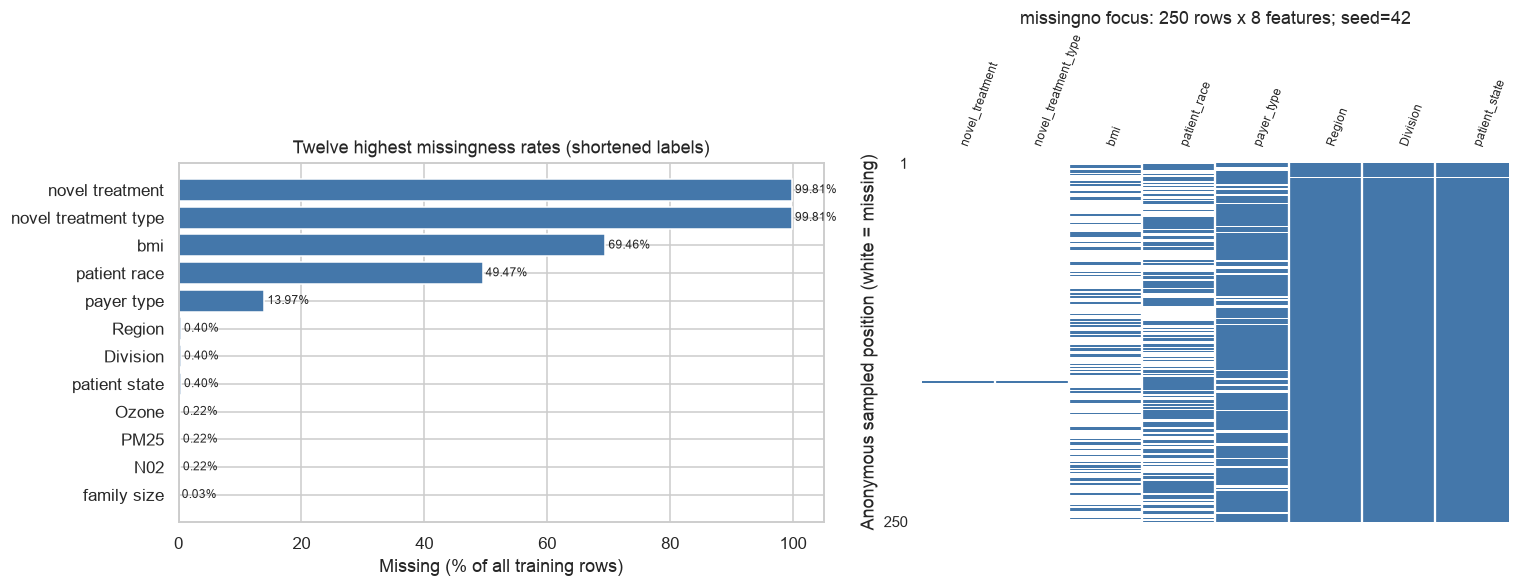

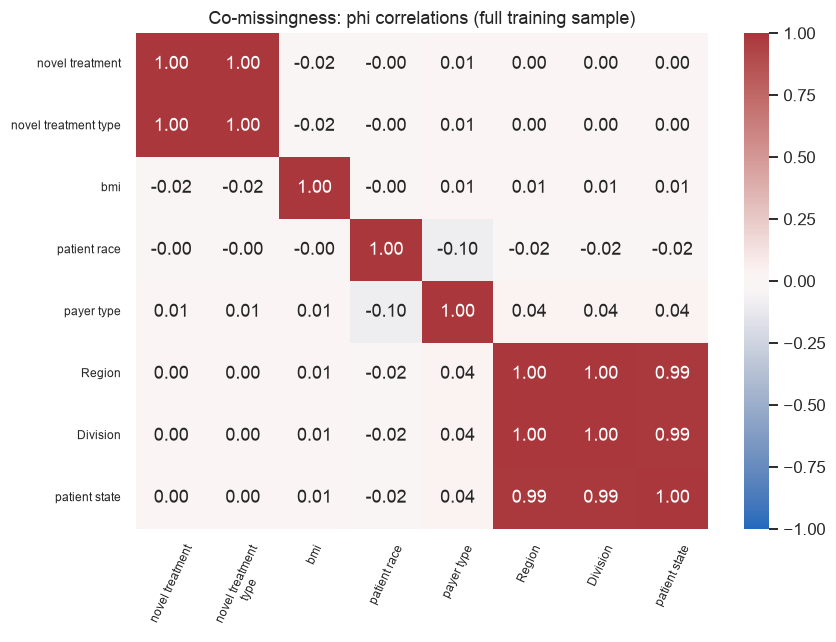

In [4]:
missing_counts = df[feature_columns].isna().sum().sort_values(ascending=False, kind="stable")
missing_table = missing_counts.rename("missing_n").to_frame()
missing_table["missing_pct"] = missing_table.missing_n / len(df) * 100
missing_table["observed_n"] = len(df) - missing_table.missing_n
with pd.option_context("display.max_rows", 90):
    display(missing_table.round(3))
row_missing = df[feature_columns].isna().sum(axis=1)
assert int(missing_counts.sum()) == int(row_missing.sum())
assert (missing_table.missing_n + missing_table.observed_n == len(df)).all()
display(row_missing.describe(percentiles=[0.5, 0.9, 0.99]).rename("missing_feature_count_per_row").to_frame())
print(f"Rows with any missing feature: {int((row_missing > 0).sum()):,} / {len(df):,} "
      f"({(row_missing > 0).mean():.2%})")

missing_columns = missing_counts[missing_counts > 0].index.tolist()
indicators = df[missing_columns].isna()
missing_focus = missing_columns[:8]
sampled_indicators = indicators[missing_focus].sample(n=min(250, len(df)), random_state=RANDOM_STATE)

plot_alias = {"metastatic_first_novel_treatment": "novel_treatment",
              "metastatic_first_novel_treatment_type": "novel_treatment_type"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
top_missing = missing_table.head(12).iloc[::-1]
axes[0].barh([fill(plot_alias.get(c, c).replace("_", " "), 30) for c in top_missing.index], top_missing.missing_pct, color="#4477AA")
axes[0].set(xlabel="Missing (% of all training rows)", xlim=(0, 105), title="Twelve highest missingness rates (shortened labels)")
for i, pct in enumerate(top_missing.missing_pct):
    axes[0].text(pct + 0.5, i, f"{pct:.2f}%", va="center", fontsize=8)
focus_matrix = df[missing_focus].sample(n=min(250, len(df)), random_state=RANDOM_STATE)
# Plot-only aliases/positions; the original frame is not renamed or reordered.
focus_matrix = focus_matrix.rename(columns=plot_alias).set_axis(range(len(focus_matrix)), axis="index")
msno.matrix(focus_matrix, ax=axes[1], sparkline=False, labels=True, fontsize=8,
            label_rotation=70, color=(0.27, 0.47, 0.67))
axes[1].set(title=f"missingno focus: {len(focus_matrix)} rows x {len(missing_focus)} features; seed={RANDOM_STATE}",
            ylabel="Anonymous sampled position (white = missing)")
plt.tight_layout()
plt.show()

# Phi = Pearson correlation between binary missingness indicators; never between raw codes.
phi = indicators[missing_focus].astype(int).corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(phi, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag",
            xticklabels=[fill(plot_alias.get(c, c).replace("_", " "), 18) for c in missing_focus],
            yticklabels=[fill(plot_alias.get(c, c).replace("_", " "), 22) for c in missing_focus], ax=ax)
ax.set_title("Co-missingness: phi correlations (full training sample)")
ax.tick_params(axis="x", rotation=65, labelsize=8)
ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.tight_layout()
plt.show()

In [5]:
pattern_keys = {column: f"M{i+1}" for i, column in enumerate(missing_focus)}
patterns = indicators[missing_focus].astype(int).astype(str).agg("".join, axis=1).value_counts()
assert int(patterns.sum()) == len(df)
assert (patterns.index.str.len() == len(missing_focus)).all()
pattern_table = patterns.head(10).rename("patients").to_frame()
pattern_table["share_pct"] = pattern_table.patients / len(df) * 100
print("Pattern order:", pattern_keys)
print("1 = missing; 0 = observed. Patterns cover only the eight selected columns.")
display(pattern_table.round(3))
print(f"Coverage of displayed patterns: {pattern_table.patients.sum()/len(df):.2%}")

missing_class_counts = indicators.groupby(df[TARGET]).sum().T.reindex(columns=[0, 1])
assert missing_class_counts.sum(axis=1).equals(missing_counts.loc[missing_columns])
missing_by_class = missing_class_counts.div(balance["patients"], axis="columns") * 100
missing_by_class.columns = ["missing_pct_class0", "missing_pct_class1"]
missing_by_class["difference_pp_class1_minus_class0"] = (
    missing_by_class.missing_pct_class1 - missing_by_class.missing_pct_class0
)
for label in [0, 1]:
    missing_by_class[f"observed_n_class{label}"] = (
        balance.loc[label, "patients"] - missing_class_counts[label]
    )
    reconstructed_n = missing_by_class[f"missing_pct_class{label}"] * balance.loc[label, "patients"] / 100
    assert np.allclose(reconstructed_n, missing_class_counts[label])
print("Class denominators:", balance["patients"].to_dict())
display(missing_by_class.loc[missing_focus].round(3))

co_missing_records = []
for left, right in [("Region", "Division"),
                    ("metastatic_first_novel_treatment", "metastatic_first_novel_treatment_type")]:
    left_missing, right_missing = df[left].isna(), df[right].isna()
    co_missing_records.append({
        "pair": f"{plot_alias.get(left, left)} / {plot_alias.get(right, right)}",
        "both_missing_n": int((left_missing & right_missing).sum()),
        "discordant_missingness_n": int((left_missing != right_missing).sum()),
        "neither_missing_n": int((~left_missing & ~right_missing).sum()),
    })
co_missing_checks = pd.DataFrame(co_missing_records).set_index("pair")
assert co_missing_checks.sum(axis=1).eq(len(df)).all()
display(co_missing_checks)
display(Markdown(
    f"**Observed:** BMI is missing in **{missing_table.loc['bmi', 'missing_pct']:.2f}%** "
    f"of rows and patient race in **{missing_table.loc['patient_race', 'missing_pct']:.2f}%**. "
    f"Only **{int(missing_table.loc['metastatic_first_novel_treatment', 'observed_n'])}** rows "
    f"have a nonmissing novel-treatment value (**{missing_table.loc['metastatic_first_novel_treatment', 'missing_pct']:.2f}% missing**). "
    f"BMI summaries use only **{int(missing_table.loc['bmi', 'observed_n']):,}/{len(df):,}** records; "
    "their distribution need not represent the unobserved cases. This extremely small observed treatment subset "
    "cannot support stable routine imputation or treatment comparisons. A missing treatment field "
    "does not mean no treatment was given. Shared missingness is compatible with shared data "
    "sources or join coverage, but this is an explanation to verify, not an identified mechanism. "
    "Differences by class describe recording patterns; they do not establish MCAR, MAR, or MNAR."
))

Pattern order: {'metastatic_first_novel_treatment': 'M1', 'metastatic_first_novel_treatment_type': 'M2', 'bmi': 'M3', 'patient_race': 'M4', 'payer_type': 'M5', 'Region': 'M6', 'Division': 'M7', 'patient_state': 'M8'}
1 = missing; 0 = observed. Patterns cover only the eight selected columns.


,patients,share_pct
11110000,3934,30.482
11100000,3707,28.723
11010000,1755,13.598
11000000,1650,12.785
11101000,791,6.129
11111000,473,3.665
11001000,325,2.518
11011000,195,1.511
11100111,21,0.163
00110000,11,0.085


Coverage of displayed patterns: 99.66%
Class denominators: {0: 4846, 1: 8060}


,missing_pct_class0,missing_pct_class1,difference_pp_class1_minus_class0,observed_n_class0,observed_n_class1
metastatic_first_novel_treatment,99.835,99.801,-0.033,8,16
metastatic_first_novel_treatment_type,99.835,99.801,-0.033,8,16
bmi,66.447,71.278,4.831,1626,2315
patient_race,52.002,47.953,-4.049,2326,4195
payer_type,10.937,15.794,4.857,4316,6787
Region,0.371,0.422,0.050,4828,8026
Division,0.371,0.422,0.050,4828,8026
patient_state,0.351,0.422,0.071,4829,8026


,both_missing_n,discordant_missingness_n,neither_missing_n
pair,,,
Region / Division,52,0,12854
novel_treatment / novel_treatment_type,12882,0,24


**Observed:** BMI is missing in **69.46%** of rows and patient race in **49.47%**. Only **24** rows have a nonmissing novel-treatment value (**99.81% missing**). BMI summaries use only **3,941/12,906** records; their distribution need not represent the unobserved cases. This extremely small observed treatment subset cannot support stable routine imputation or treatment comparisons. A missing treatment field does not mean no treatment was given. Shared missingness is compatible with shared data sources or join coverage, but this is an explanation to verify, not an identified mechanism. Differences by class describe recording patterns; they do not establish MCAR, MAR, or MNAR.

### Required missingno overview

The overview uses every training row and every semantic feature (no ID or target), without
sampling. Short IDs F01…F81 identify columns; the complete key remains accessible below. The
focused matrix above uses 250 sampled rows, seed 42. Rare gaps may be invisible at overview
resolution or absent from a sample; full-data counts take precedence. Neither view identifies
MCAR/MAR/MNAR. No values are imputed to draw these figures.

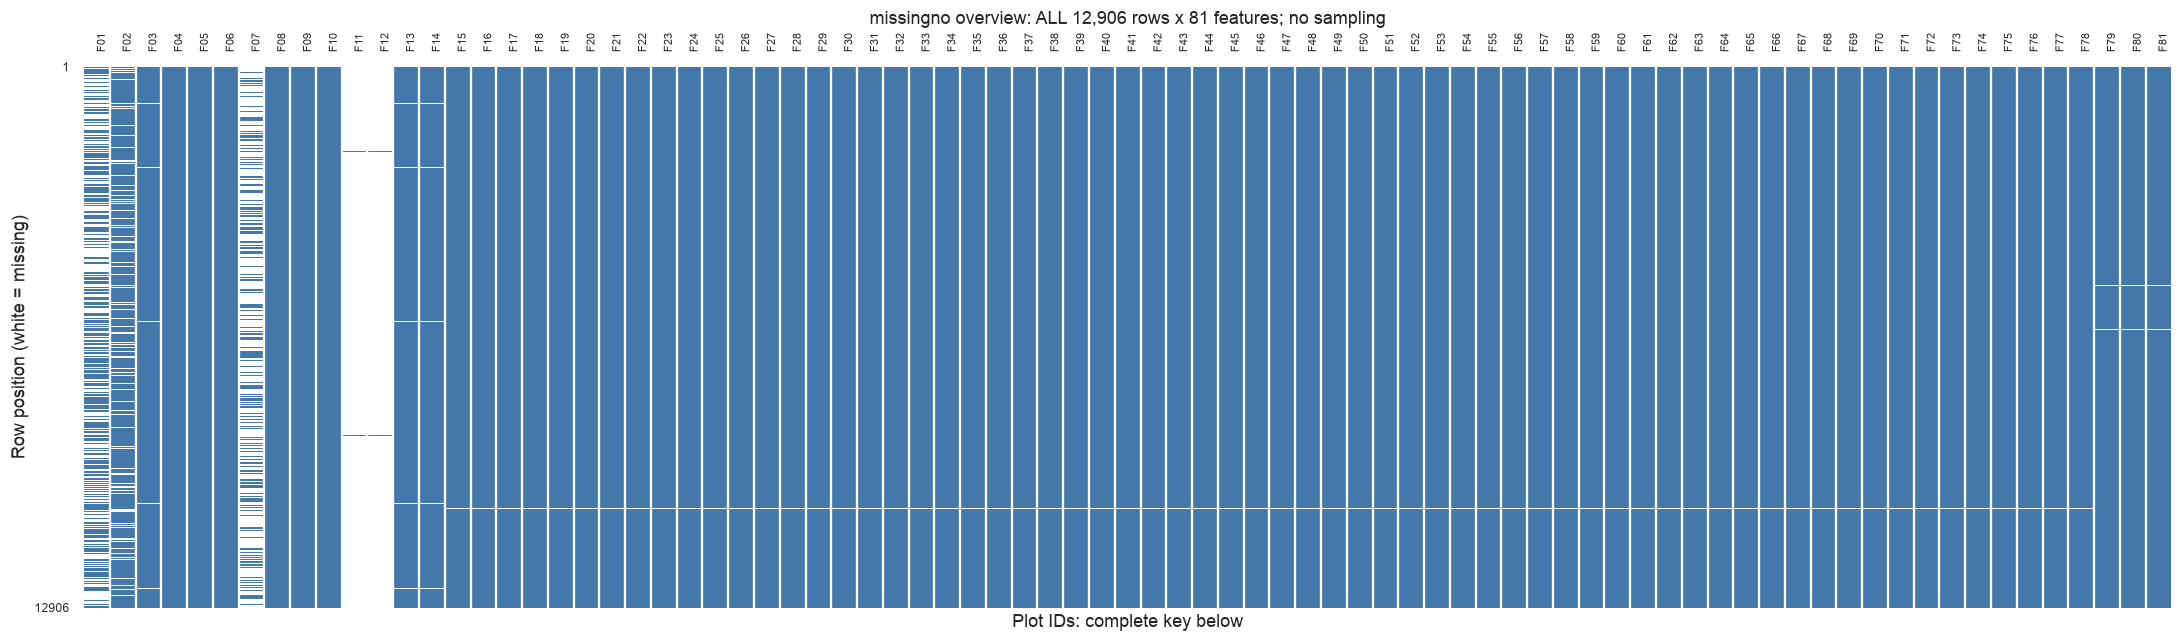

,plot_id,feature
0,F01,patient_race
1,F02,payer_type
2,F03,patient_state
3,F04,patient_zip3
4,F05,patient_age
5,F06,patient_gender
6,F07,bmi
7,F08,breast_cancer_diagnosis_code
8,F09,breast_cancer_diagnosis_desc
9,F10,metastatic_cancer_diagnosis_code


missingno version: 0.5.2


In [6]:
missingno_key = pd.DataFrame({"plot_id": [f"F{i+1:02}" for i in range(len(feature_columns))],
                                 "feature": feature_columns})
overview = df[feature_columns].set_axis(missingno_key.plot_id, axis="columns")
fig, ax = plt.subplots(figsize=(20, 6))
msno.matrix(overview, ax=ax, sparkline=False, labels=True, fontsize=7,
            label_rotation=90, color=(0.27, 0.47, 0.67))
ax.set(title=f"missingno overview: ALL {len(df):,} rows x {len(feature_columns)} features; no sampling",
       xlabel="Plot IDs: complete key below", ylabel="Row position (white = missing)")
plt.tight_layout()
plt.show()
with pd.option_context("display.max_rows", None):
    display(missingno_key)
print("missingno version:", version("missingno"))


### Little's MCAR test: declared numerical scope and calibrated-inference limit

H0: missingness is MCAR; H1: it is not MCAR. Here MCAR means the missingness pattern is independent
of both observed and unobserved values. MAR permits dependence on observed information, conditional
on which missingness does not depend on unobserved values. MNAR retains dependence on unobserved
values after conditioning on observed information. Observed-data tests cannot generally distinguish
MAR from MNAR. Failure to reject MCAR is not proof that MCAR holds.

**Scope fixed before this calculation:** `patient_age`, `bmi`, the two candidate individual
numerical measurements. Age is fully observed and provides a comparator for BMI recording.
Exclude ID, target, ZIP/category/code/text fields, sparse treatment fields, and the contextual
numerical variables with shared ZIP values/compositional dependencies. This is a two-variable
subproblem, not a test of all 81 features; there is no p-value-directed search over scopes.

`src/little_mcar.py` uses only permitted NumPy/SciPy dependencies. Gaussian EM estimates the common
observed-data ML mean/covariance; the test is
\(D^2=\sum_j n_j(\bar x_{j,o}-\hat\mu_o)^T\hat\Sigma_{oo}^{-1}(\bar x_{j,o}-\hat\mu_o)\),
with \(df=\sum_j p_j-p\). No pairwise-covariance shortcut, regularization, pseudoinverse, or
indicator/target chi-square is substituted. EM's internal expected sufficient statistics are
not a preprocessing imputation and no completed dataset is returned or saved.

Algorithm/formula were checked against [naniar's ML-based implementation and reference](https://naniar.njtierney.com/reference/mcar_test.html).
Local tests check a closed-form special case, unit/row-order invariance, general patterns and
invalid numerical inputs. The public `airquality` reference check yielded 35.1061749, df=14,
p=0.00141776, four patterns, matching the published rounded example. The latter is an external
implementation check, not a WiDS result; it is not fetched when running this notebook.

**Calibration limitation:** a Gaussian/common-covariance, independent-row reference is used.
Age is discrete/bounded, BMI is selected by heavy missingness, and geographic clustering may
violate independence. The later marginal normality tests do not establish joint normality.
Therefore the numerical reference is reported, but an assumption-supported MCAR verdict for
this cohort is **BLOCKED**. Numerical failure is also BLOCKED, with the actual error. Do not
turn a non-significant reference probability into a global MCAR label, or a rejection into MAR/MNAR.
This mean-pattern test can miss mechanisms that change covariance or unobserved distributional features without changing the observed means. In the selected two-variable scope, age is complete and the information is primarily age contrasts across BMI-recording patterns; it does not validate unobserved BMI values. The target was intentionally excluded, so a different missing-indicator/target result is not a contradiction.


In [7]:
from src.little_mcar import little_mcar

little_included = ["patient_age", "bmi"]
little_exclusion_groups = pd.DataFrame([
    {"excluded_features": sorted(clinical_review), "reason": "clinical code/text; sparse treatment and unverified timing"},
    {"excluded_features": sorted(geographic_codes | individual_categorical), "reason": "nominal/code variables; Gaussian numerical model inappropriate"},
    {"excluded_features": [c for c in continuous_columns if c not in little_included],
     "reason": "contextual/shared-ZIP numerical variables; dependence and singular/compositional covariance risk"},
    {"excluded_features": [ID, TARGET], "reason": "identifier and outcome; not candidate numerical measurements"},
])
with pd.option_context("display.max_colwidth", None):
    display(little_exclusion_groups)
little_report = {
    "method/library": "Little (1988) mean-pattern statistic; local Gaussian ML/EM; NumPy/SciPy",
    "included_features": little_included,
    "excluded_features/reasons": "Full grouped exclusions shown above; no p-value-driven subset search",
    "n_rows": len(df), "missing_patterns": np.nan, "test_statistic": np.nan,
    "degrees_of_freedom": np.nan, "p_value": np.nan,
    "decision": "BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported",
    "assumptions": "independent observations; identifiable common Gaussian mean/covariance; chi-square asymptotics",
    "limitations": "limited two-variable scope; bounded age, nonnormal BMI, shared-ZIP dependence; no global mechanism classification",
}
try:
    little_result = little_mcar(df[little_included].to_numpy(dtype=float))
    little_report.update({"missing_patterns": little_result["missing_patterns"],
                          "test_statistic": little_result["statistic"],
                          "degrees_of_freedom": little_result["degrees_of_freedom"],
                          "p_value": little_result["p_value"],
                          "normal_reference_decision": "reject H0" if little_result["p_value"] < ALPHA else "fail to reject H0",
                          "EM_iterations": little_result["iterations"],
                          "EM_converged": little_result["converged"],
                          "covariance_condition": little_result["covariance_condition"]})
    display(pd.DataFrame(little_result["pattern_details"]))
except (ValueError, ArithmeticError, RuntimeError, np.linalg.LinAlgError) as error:
    little_report["decision"] = "BLOCKED: " + str(error)
    little_report["normal_reference_decision"] = "NOT TESTABLE"
    little_result = None
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(little_report, name="actual_result").to_frame())
if little_result is not None:
    display(Markdown(
        f"**Computed reference:** D²={little_result['statistic']:.6f}, "
        f"df={little_result['degrees_of_freedom']}, p={little_result['p_value']:.6g}; "
        f"**{little_report['normal_reference_decision']}** at alpha={ALPHA}. "
        "This is conditional on the working reference model, not an established MCAR mechanism. "
        "The formal cohort-wide conclusion remains **BLOCKED** by calibration/scope limitations. "
        "Existing missing-by-target Fisher tests are different questions and do not replace Little's test."
    ))


,excluded_features,reason
0,"[breast_cancer_diagnosis_code, breast_cancer_diagnosis_desc, metastatic_cancer_diagnosis_code, metastatic_first_novel_treatment, metastatic_first_novel_treatment_type]",clinical code/text; sparse treatment and unverified timing
1,"[Division, Region, patient_gender, patient_race, patient_state, patient_zip3, payer_type]",nominal/code variables; Gaussian numerical model inappropriate
2,"[population, density, age_median, age_under_10, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_over_80, male, female, married, divorced, never_married, widowed, family_size, family_dual_income, income_household_median, income_household_under_5, income_household_5_to_10, income_household_10_to_15, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_75_to_100, income_household_100_to_150, income_household_150_over, income_household_six_figure, income_individual_median, home_ownership, housing_units, home_value, rent_median, rent_burden, education_less_highschool, education_highschool, education_some_college, education_bachelors, education_graduate, education_college_or_above, education_stem_degree, labor_force_participation, unemployment_rate, self_employed, farmer, race_white, race_black, race_asian, race_native, race_pacific, race_other, race_multiple, hispanic, disabled, poverty, limited_english, commute_time, health_uninsured, veteran, Ozone, PM25, N02]",contextual/shared-ZIP numerical variables; dependence and singular/compositional covariance risk
3,"[patient_id, DiagPeriodL90D]",identifier and outcome; not candidate numerical measurements


,observed_mask,n_rows,observed_dimensions,contribution
0,"[True, False]",8965,1,1.070762
1,"[True, True]",3941,2,2.435772


,actual_result
method/library,Little (1988) mean-pattern statistic; local Gaussian ML/EM; NumPy/SciPy
included_features,"[patient_age, bmi]"
excluded_features/reasons,Full grouped exclusions shown above; no p-value-driven subset search
n_rows,12906
missing_patterns,2
test_statistic,3.506534
degrees_of_freedom,1
p_value,0.061127
decision,BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported
assumptions,independent observations; identifiable common Gaussian mean/covariance; chi-square asymptotics


**Computed reference:** D²=3.506534, df=1, p=0.0611272; **fail to reject H0** at alpha=0.05. This is conditional on the working reference model, not an established MCAR mechanism. The formal cohort-wide conclusion remains **BLOCKED** by calibration/scope limitations. Existing missing-by-target Fisher tests are different questions and do not replace Little's test.

### Literal tokens versus confirmed missing values

A second **read-only lexical read** preserves blanks and common candidate tokens that pandas
may already interpret as NA. The token set is deliberately a generic review list, **not** a WiDS
sentinel dictionary. Values such as `999` may be legitimate measurements or codes. Matching a
candidate does not establish missingness; no replacement or clinical interpretation follows.

In [8]:
lexical = pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False)
candidate_tokens = {"", "na", "n/a", "nan", "null", "none", "unknown", "missing", "?", "-9", "-99", "-999", "999", "9999"}
sentinel_records = []
for column in feature_columns:
    counts = lexical[column].str.strip().str.casefold().value_counts()
    for token, count in counts[counts.index.isin(candidate_tokens)].items():
        sentinel_records.append({"feature": column, "literal_token": "[empty field]" if token == "" else token,
                                 "count": int(count),
                                 "status": ("identifier token retained; not classified as missing"
                                            if column in geographic_codes and token != ""
                                            else "candidate only; unverified")})
sentinel_review = pd.DataFrame(sentinel_records, columns=["feature", "literal_token", "count", "status"])
display(sentinel_review.sort_values("count", ascending=False).head(20))
nonblank_matches = sentinel_review.loc[sentinel_review.literal_token != "[empty field]"]
print("Nonempty candidate-token matches across columns:", int(nonblank_matches['count'].sum()))
display(nonblank_matches)
assert df.patient_zip3.eq("999").sum() == zip_literal_999_n
print("The literal ZIP code 999 remains observed; no missing-value replacement was made.")
print("Twenty largest token/column counts shown. Absence from this list does not verify other codes.")

,feature,literal_token,count,status
6,metastatic_first_novel_treatment_type,[empty field],12882,candidate only; unverified
5,metastatic_first_novel_treatment,[empty field],12882,candidate only; unverified
4,bmi,[empty field],8965,candidate only; unverified
0,patient_race,[empty field],6385,candidate only; unverified
1,payer_type,[empty field],1803,candidate only; unverified
7,Region,[empty field],52,candidate only; unverified
8,Division,[empty field],52,candidate only; unverified
2,patient_state,[empty field],51,candidate only; unverified
31,income_household_5_to_10,[empty field],4,candidate only; unverified
40,income_household_150_over,[empty field],4,candidate only; unverified


Nonempty candidate-token matches across columns: 1


,feature,literal_token,count,status
3,patient_zip3,999,1,identifier token retained; not classified as m...


The literal ZIP code 999 remains observed; no missing-value replacement was made.
Twenty largest token/column counts shown. Absence from this list does not verify other codes.


## 5. Numerical distributions and preliminary outlier exploration

**Questions:** how dispersed or skewed are appropriate numerical candidates, and which values
merit later domain review? Summary statistics ignore missing observations and show their own
observed counts. Six columns are shown for semantic breadth rather than a significance-screening rule;
their units remain unverified. Context distributions are **patient-weighted**, so large patient
clusters can repeat the same area-level value.

Pandas' sample skewness uses its bias-corrected convention and omits missing values. It is
sensitive to sample size and extreme observations, not a requirement to transform data. Tukey fences
`Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR` flag unusual observations relative to each empirical
marginal distribution. Flags are **not** confirmed errors, clinical cutoffs, or instructions to
remove/winsorize records. A zero IQR makes this simple diagnostic unsuitable and is marked explicitly.

,count,mean,std,min,25%,50%,75%,max,missing_pct,sample_skewness
patient_age,12906.0,59.183,13.335,18.000,50.000,59.000,67.000,91.000,0.000,0.128
bmi,3941.0,28.985,5.697,14.000,24.660,28.190,32.920,85.000,69.464,0.737
population,12905.0,20744.441,13886.904,635.545,9463.897,19154.190,30021.279,71374.132,0.008,0.998
density,12905.0,1581.950,2966.305,0.917,171.857,700.338,1666.515,21172.000,0.008,4.040
age_median,12905.0,40.502,4.037,20.600,37.130,40.639,42.935,54.570,0.008,0.294
age_under_10,12905.0,11.123,1.512,0.000,10.160,11.039,12.190,17.675,0.008,-0.110
age_10_to_19,12905.0,12.945,1.924,6.314,11.741,12.924,14.020,35.300,0.008,1.257
age_20s,12905.0,13.290,3.354,5.925,11.013,12.538,14.971,62.100,0.008,2.117
age_30s,12905.0,12.862,2.325,1.500,11.292,12.443,14.027,25.471,0.008,0.955
age_40s,12905.0,12.067,1.248,0.800,11.340,12.124,12.892,17.820,0.008,-0.326


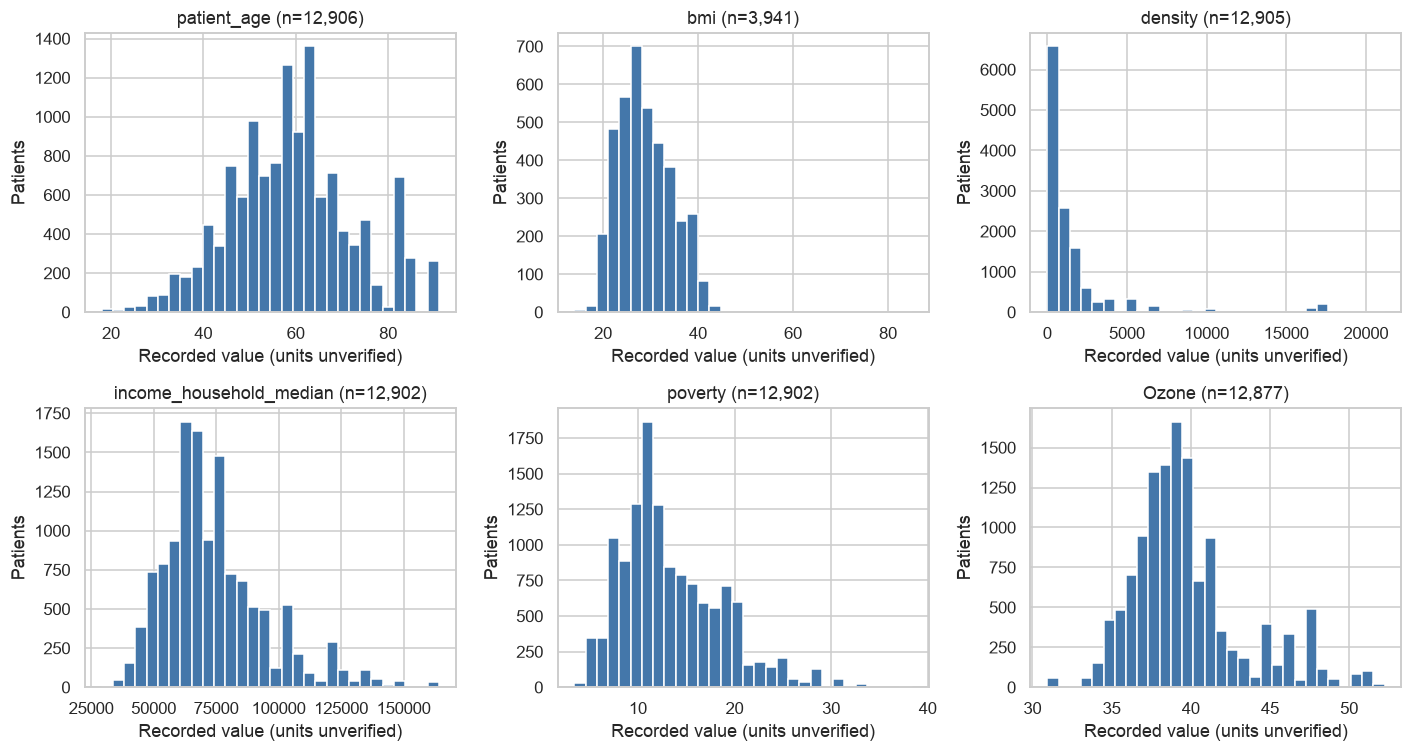

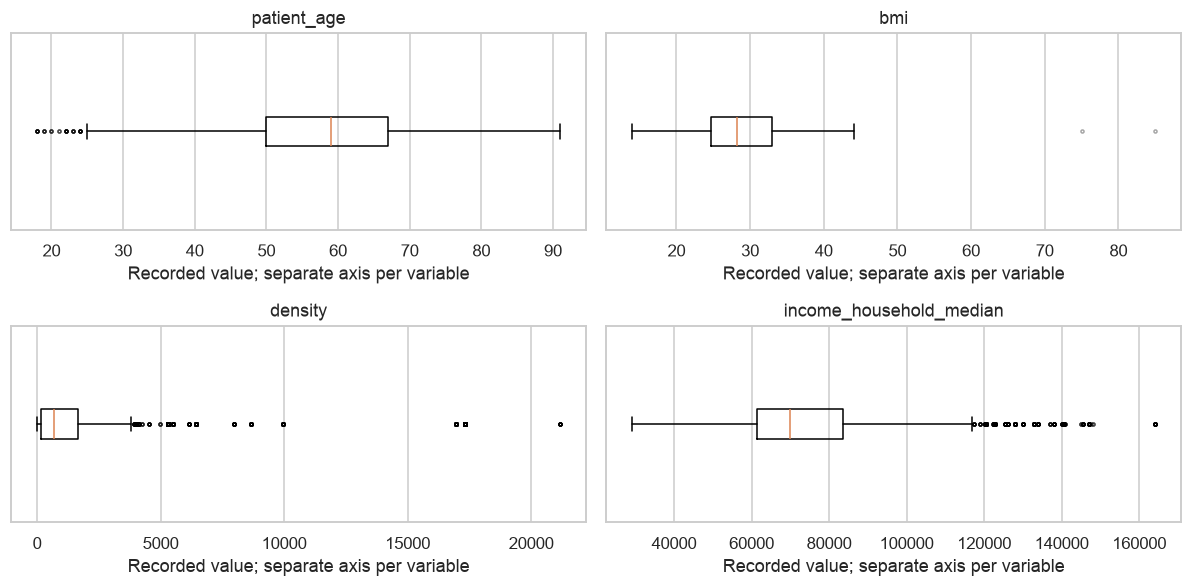

,observed_n,IQR,lower_fence,upper_fence,flagged_n,flagged_pct_observed,diagnostic_status
feature,,,,,,,
race_native,12905,0.577,-0.653,1.656,1246,9.655,assessed
Ozone,12877,3.438,32.542,46.293,1194,9.272,assessed
farmer,12902,2.273,-3.367,5.726,1178,9.130,assessed
race_asian,12905,5.970,-7.859,16.022,1159,8.981,assessed
home_value,12902,238121.796,-189422.239,763064.943,1148,8.898,assessed
limited_english,12902,4.982,-6.478,13.448,1130,8.758,assessed
density,12905,1494.658,-2070.130,3908.503,1092,8.462,assessed
race_pacific,12905,0.123,-0.160,0.330,1027,7.958,assessed
race_other,12905,6.604,-8.592,17.824,846,6.556,assessed


**Observed:** density skewness is **4.04**, versus **0.13** for patient age. BMI ranges from **14.00** to **85.00** among observed records; **2** observed BMI values exceed the empirical Tukey fences. Right tails motivate later sensitivity checks, not automatic log transforms or deletion. No clinical plausibility verdict is possible without verified units and source records.

In [9]:
numerical_summary = df[continuous_columns].describe(percentiles=[0.25, 0.5, 0.75]).T
numerical_summary["missing_pct"] = df[continuous_columns].isna().mean() * 100
numerical_summary["sample_skewness"] = df[continuous_columns].skew()
with pd.option_context("display.max_rows", 80):
    display(numerical_summary.round(3))

numerical_focus = ["patient_age", "bmi", "density", "income_household_median", "poverty", "Ozone"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, column in zip(axes.flat, numerical_focus):
    values = df.loc[df[column].notna(), column]
    ax.hist(values, bins=30, color="#4477AA", edgecolor="white")
    ax.set(title=f"{column} (n={len(values):,})", xlabel="Recorded value (units unverified)", ylabel="Patients")
plt.tight_layout()
plt.show()

box_focus = ["patient_age", "bmi", "density", "income_household_median"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5))
for ax, column in zip(axes.flat, box_focus):
    values = df.loc[df[column].notna(), column]
    ax.boxplot(values, orientation="horizontal", flierprops={"markersize": 2, "alpha": 0.35})
    ax.set(title=column, xlabel="Recorded value; separate axis per variable", yticks=[])
plt.tight_layout()
plt.show()

outlier_records = []
for column in continuous_columns:
    values = df.loc[df[column].notna(), column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged_n = int(((values < lower) | (values > upper)).sum()) if iqr > 0 else np.nan
    outlier_records.append({"feature": column, "observed_n": len(values), "IQR": iqr,
                            "lower_fence": lower, "upper_fence": upper,
                            "flagged_n": flagged_n,
                            "flagged_pct_observed": flagged_n/len(values)*100 if len(values) else np.nan,
                            "diagnostic_status": "assessed" if iqr > 0 else "not assessed: zero/undefined IQR"})
outlier_review = pd.DataFrame(outlier_records).set_index("feature")
display(outlier_review.sort_values("flagged_pct_observed", ascending=False).head(12).round(3))
display(Markdown(
    f"**Observed:** density skewness is **{numerical_summary.loc['density', 'sample_skewness']:.2f}**, "
    f"versus **{numerical_summary.loc['patient_age', 'sample_skewness']:.2f}** for patient age. "
    f"BMI ranges from **{numerical_summary.loc['bmi', 'min']:.2f}** to "
    f"**{numerical_summary.loc['bmi', 'max']:.2f}** among observed records; "
    f"**{outlier_review.loc['bmi', 'flagged_n']:.0f}** observed BMI values exceed the empirical Tukey fences. "
    "Right tails motivate later sensitivity checks, not automatic log transforms or deletion. "
    "No clinical plausibility verdict is possible without verified units and source records."
))

### Required normality tests across every numerical candidate

H0: the feature's observed values follow a normal distribution; H1: they do not. Follow the
assignment's sample-size rule on each feature's **nonmissing** count: Shapiro–Wilk for
3 ≤ n ≤ 5000; D’Agostino–Pearson for n > 5000. Alpha is 0.05 (the official page does not state a
different alpha). Insufficient data, infinite values, constant variables, or invalid test results
are NOT TESTABLE with reasons. NaNs are omitted for that feature only; the training frame is unchanged.

The complete table is displayed, not just a top-k selection. Decisions use raw p-values to meet
the requested per-feature classification; they do not provide family-wide error control over
69 simultaneous tests. A small p-value is evidence against the normal-reference null, not the
size of departure. Large samples detect small deviations; bounded/discrete measures, selected
observed cases and repeated ZIP-level values undermine simple iid interpretation. “Fail to reject”
is not “proved normal”, and marginal tests do not establish a multivariate Gaussian model.

StandardScaler changes location/scale, not distributional shape. MinMaxScaler and RobustScaler
also do not Gaussianize data. A rejection does not mandate any scaler. The table of candidates
below defines later comparisons only; learned transforms must be fit within development folds.
See [Shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) and
[normaltest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html).
D’Agostino’s chi-square reference has two degrees of freedom, so log(p) = -statistic/2. This remains representable when SciPy’s probability underflows; the displayed table flags underflow rather than printing an exact-zero probability. Shapiro log(p) is computed from its returned probability.


In [10]:
normality_records = []
for column in continuous_columns:
    values = df.loc[df[column].notna(), column].to_numpy(dtype=float)
    n_observed = len(values)
    record = {"feature": column, "n_observed": n_observed,
              "missing_pct": df[column].isna().mean() * 100,
              "test_name": "NOT TESTABLE", "statistic": np.nan, "p_value": np.nan,
              "decision": "NOT TESTABLE", "log_p_value": np.nan, "limitations": "iid calibration; marginal observed cases only"}
    reason = None
    if n_observed < 3:
        reason = "fewer than 3 observed values"
    elif not np.isfinite(values).all():
        reason = "non-finite observed values; not silently removed"
    elif np.ptp(values) == 0:
        reason = "zero observed variance"
    if reason is None:
        record["test_name"] = "Shapiro-Wilk" if n_observed <= 5000 else "D'Agostino-Pearson"
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result = stats.shapiro(values) if n_observed <= 5000 else stats.normaltest(values)
            if not np.isfinite(result.statistic) or not np.isfinite(result.pvalue) or not 0 <= result.pvalue <= 1:
                raise ArithmeticError("invalid statistic/probability")
            # normaltest uses a chi-square reference with df=2: log survival = -K2/2.
            # Preserve SciPy's raw probability, but do not print an underflow as exact zero.
            log_p = (-0.5 * float(result.statistic) if n_observed > 5000
                     else float(np.log(result.pvalue)) if result.pvalue > 0 else -np.inf)
            record.update(statistic=float(result.statistic), p_value=float(result.pvalue), log_p_value=log_p,
                          decision="reject H0" if result.pvalue < ALPHA else "fail to reject H0")
            if caught:
                record["limitations"] += "; " + "; ".join(str(w.message) for w in caught)
            if result.pvalue == 0:
                record["limitations"] += "; p underflow: returned 0 is not an exact zero probability"
        except (ValueError, ArithmeticError, FloatingPointError) as error:
            reason = str(error)
    if reason:
        record["decision"] = "NOT TESTABLE"
        record["limitations"] = reason
    normality_records.append(record)
normality_table = pd.DataFrame(normality_records).set_index("feature")
assert len(normality_table) == len(continuous_columns)
with pd.option_context("display.max_rows", None):
    display(normality_table.style.format({"missing_pct": "{:.3f}", "statistic": "{:.6g}", "p_value": lambda p: "UNDERFLOW (see log_p)" if p == 0 else f"{p:.4e}", "log_p_value": "{:.4f}"}))
normality_counts = normality_table.decision.value_counts().reindex(
    ["reject H0", "fail to reject H0", "NOT TESTABLE"], fill_value=0)
display(normality_counts.rename("feature_count").to_frame())
display(normality_table.test_name.value_counts().rename("feature_count").to_frame())
scaling_candidates = pd.DataFrame([
    {"candidate": "StandardScaler (Z-score)", "reason_to_compare": "common location/variance baseline even for nonnormal variables",
     "limitation": "affine; does not create normality; sensitive to extreme values"},
    {"candidate": "MinMaxScaler", "reason_to_compare": "when bounded numeric ranges suit the later estimator",
     "limitation": "affine; no Gaussianization; range depends on extremes and training-fold support"},
    {"candidate": "RobustScaler", "reason_to_compare": "median/IQR scale baseline for heavy-tailed or extreme-value-sensitive variables",
     "limitation": "does not remove outliers or create normality; check zero IQR"},
    {"candidate": "QuantileTransformer: uniform and normal outputs", "reason_to_compare": "nonlinear rank-based marginal transformation comparison required later",
     "limitation": "changes geometry/interpretation; fit fold-locally; no optimality inferred from a p-value"},
])
display(scaling_candidates)
display(Markdown(
    f"**Observed normality-reference decisions:** {normality_counts['reject H0']} reject, "
    f"{normality_counts['fail to reject H0']} fail to reject, {normality_counts['NOT TESTABLE']} not testable. "
    "These results motivate controlled comparisons of the listed methods, not an automatic scaler choice."
))

print("Raw SciPy p-value underflows:", int(normality_table.p_value.eq(0).sum()), "; inspect log_p_value, not literal zero probabilities.")


,n_observed,missing_pct,test_name,statistic,p_value,decision,log_p_value,limitations
feature,,,,,,,,
patient_age,12906,0.000,D'Agostino-Pearson,42.1018,7.2063e-10,reject H0,-21.0509,iid calibration; marginal observed cases only
bmi,3941,69.464,Shapiro-Wilk,0.960251,1.4273e-31,reject H0,-71.0244,iid calibration; marginal observed cases only
population,12905,0.008,D'Agostino-Pearson,1895.31,UNDERFLOW (see log_p),reject H0,-947.6541,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
density,12905,0.008,D'Agostino-Pearson,10620.8,UNDERFLOW (see log_p),reject H0,-5310.3995,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_median,12905,0.008,D'Agostino-Pearson,189.63,6.6443e-42,reject H0,-94.8148,iid calibration; marginal observed cases only
age_under_10,12905,0.008,D'Agostino-Pearson,305.847,3.8555e-67,reject H0,-152.9237,iid calibration; marginal observed cases only
age_10_to_19,12905,0.008,D'Agostino-Pearson,4315.48,UNDERFLOW (see log_p),reject H0,-2157.7399,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_20s,12905,0.008,D'Agostino-Pearson,6772.6,UNDERFLOW (see log_p),reject H0,-3386.2980,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_30s,12905,0.008,D'Agostino-Pearson,1847.1,UNDERFLOW (see log_p),reject H0,-923.5501,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability


,feature_count
decision,
reject H0,69
fail to reject H0,0
NOT TESTABLE,0


,feature_count
test_name,
D'Agostino-Pearson,68
Shapiro-Wilk,1


,candidate,reason_to_compare,limitation
0,StandardScaler (Z-score),common location/variance baseline even for non...,affine; does not create normality; sensitive t...
1,MinMaxScaler,when bounded numeric ranges suit the later est...,affine; no Gaussianization; range depends on e...
2,RobustScaler,median/IQR scale baseline for heavy-tailed or ...,does not remove outliers or create normality; ...
3,QuantileTransformer: uniform and normal outputs,nonlinear rank-based marginal transformation c...,changes geometry/interpretation; fit fold-loca...


**Observed normality-reference decisions:** 69 reject, 0 fail to reject, 0 not testable. These results motivate controlled comparisons of the listed methods, not an automatic scaler choice.

Raw SciPy p-value underflows: 39 ; inspect log_p_value, not literal zero probabilities.


## 6. Categorical distributions, cardinality, and rare values

**Questions:** how many observed levels exist, and is their support sufficient for later analysis?
This section includes numeric-looking geographic codes and diagnosis/treatment text. A “rare”
level is defined for this diagnostic as **less than 1% of the nonmissing rows of that column**;
it is not a pooling rule. Missing rows are counted separately and are not silently made a new class.
Plots show at most ten levels, explicitly reporting coverage; undisplayed levels are not recoded.

A fixed 1% cutoff is especially blunt when cardinality is high: even a uniform distribution
assigns only `1 / number_of_levels` to each level. For ZIP, compare this relative cutoff with
absolute supports `<5` and `<20` below. These are illustrative diagnostics, not validated pooling
thresholds or the chi-square expected-cell rule. Any future grouping threshold must be justified
by the task and learned from each training fold; unknown ZIPs also need a declared policy.

,observed_n,missing_n,cardinality,largest_level_pct_observed,rare_levels_lt_1pct,rows_in_rare_levels,rare_rows_pct_observed
feature,,,,,,,
patient_zip3,12906,0,739,1.852,733,11892,92.143
patient_state,12855,51,50,18.965,29,1228,9.553
breast_cancer_diagnosis_code,12906,0,50,15.357,32,815,6.315
breast_cancer_diagnosis_desc,12906,0,50,15.357,32,815,6.315
metastatic_cancer_diagnosis_code,12906,0,43,54.641,31,626,4.850
Division,12854,52,9,22.740,1,5,0.039
patient_race,6521,6385,5,55.022,0,0,0.000
Region,12854,52,4,30.489,0,0,0.000
payer_type,11103,1803,3,54.328,0,0,0.000


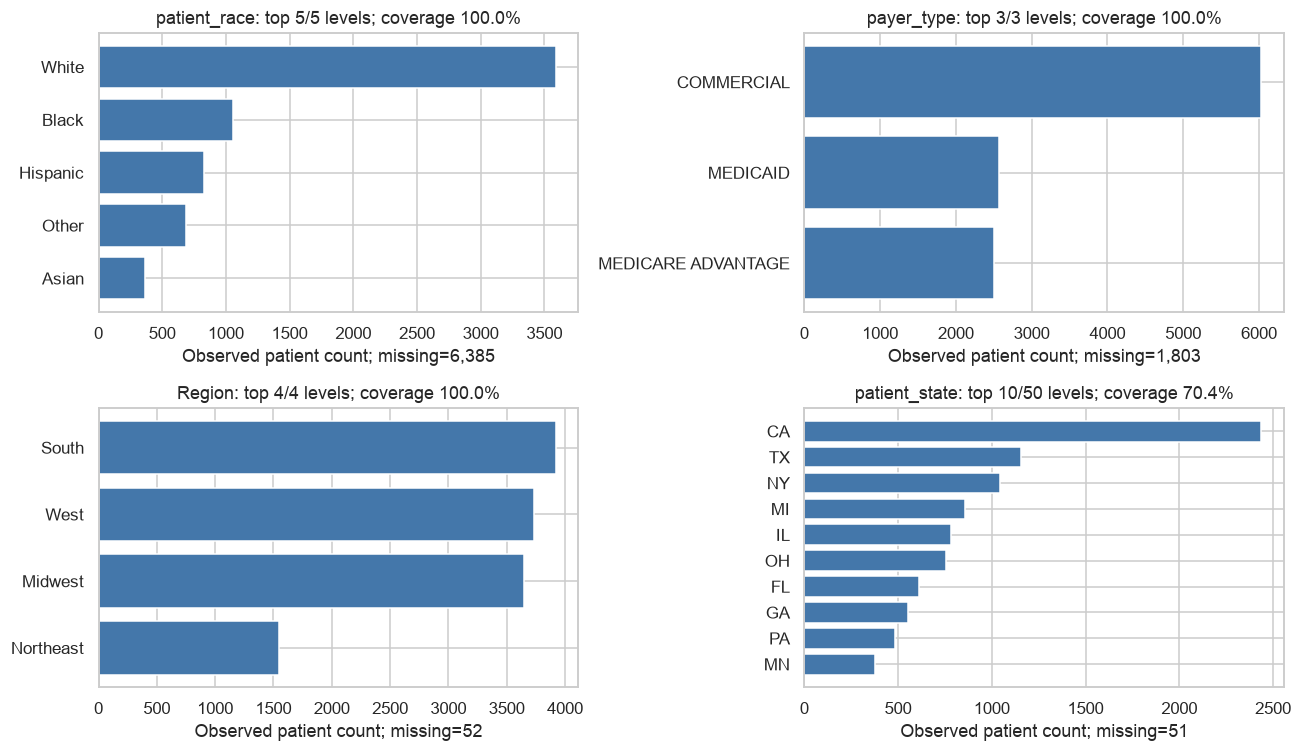

,flagged_levels,flagged_levels_pct,patients_in_flagged_levels,patients_pct
diagnostic_rule,,,,
share < 1%,733,99.188,11892,92.143
count < 5,201,27.199,470,3.642
count < 20,549,74.290,3972,30.776


Uniform share at this cardinality: 0.135% per ZIP.


,feature,literal_level,patients,pct_observed
0,patient_zip3,163,1,0.0077
1,patient_zip3,678,1,0.0077
2,patient_zip3,162,1,0.0077
3,patient_zip3,664,1,0.0077
4,patient_zip3,149,1,0.0077
5,breast_cancer_diagnosis_code,C50421,1,0.0077
6,breast_cancer_diagnosis_code,1759,1,0.0077
7,breast_cancer_diagnosis_code,C50,1,0.0077
8,breast_cancer_diagnosis_code,C5031,1,0.0077
9,breast_cancer_diagnosis_code,C50021,1,0.0077


**Observed:** ZIP has **739** categories; **733** fall below the stated 1% threshold. That relative rule covers **92.14%** of patients. In contrast, count <5 flags **201** ZIPs and **3.64%** of patients. Pooling every <1% ZIP would collapse most geographic distinctions; EDA does not justify that choice. The rare-level table shows only five smallest levels per selected column, with literal tokens, not disease-code definitions. High cardinality and small support suggest later review of regularization, grouping, or split design; no encoding or pooling is implemented.

In [11]:
category_records = []
for column in categorical_columns:
    counts = df[column].value_counts()
    shares = counts / counts.sum() if counts.sum() else counts.astype(float)
    rare = counts.loc[shares < RARE_SHARE]
    category_records.append({
        "feature": column, "observed_n": int(counts.sum()), "missing_n": int(df[column].isna().sum()),
        "cardinality": len(counts),
        "largest_level_pct_observed": shares.max() * 100 if len(shares) else np.nan,
        "rare_levels_lt_1pct": len(rare), "rows_in_rare_levels": int(rare.sum()),
        "rare_rows_pct_observed": rare.sum()/counts.sum()*100 if counts.sum() else np.nan,
    })
category_summary = pd.DataFrame(category_records).set_index("feature")
display(category_summary.sort_values("cardinality", ascending=False).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.flat, ["patient_race", "payer_type", "Region", "patient_state"]):
    counts = df[column].value_counts()
    shown = counts.head(10).iloc[::-1]
    ax.barh(shown.index.astype(str), shown, color="#4477AA")
    ax.set(title=f"{column}: top {len(shown)}/{len(counts)} levels; coverage {shown.sum()/counts.sum():.1%}",
           xlabel=f"Observed patient count; missing={df[column].isna().sum():,}")
plt.tight_layout()
plt.show()

zip_counts = df.patient_zip3.value_counts()
zip_support_records = []
for rule, mask in [
    ("share < 1%", zip_counts / zip_counts.sum() < RARE_SHARE),
    ("count < 5", zip_counts < 5),
    ("count < 20", zip_counts < 20),
]:
    zip_support_records.append({
        "diagnostic_rule": rule, "flagged_levels": int(mask.sum()),
        "flagged_levels_pct": mask.mean() * 100,
        "patients_in_flagged_levels": int(zip_counts.loc[mask].sum()),
        "patients_pct": zip_counts.loc[mask].sum() / zip_counts.sum() * 100,
    })
zip_support = pd.DataFrame(zip_support_records).set_index("diagnostic_rule")
display(zip_support.round(3))
print(f"Uniform share at this cardinality: {100 / len(zip_counts):.3f}% per ZIP.")

rare_examples = []
for column in ["patient_zip3", "breast_cancer_diagnosis_code", "metastatic_cancer_diagnosis_code"]:
    counts = df[column].value_counts()
    rare_counts = counts.loc[counts / counts.sum() < RARE_SHARE].sort_values()
    for level, count in rare_counts.head(5).items():
        rare_examples.append({"feature": column, "literal_level": str(level), "patients": int(count),
                              "pct_observed": count/counts.sum()*100})
display(pd.DataFrame(rare_examples).round(4))
display(Markdown(
    f"**Observed:** ZIP has **{int(category_summary.loc['patient_zip3', 'cardinality'])}** categories; "
    f"**{int(category_summary.loc['patient_zip3', 'rare_levels_lt_1pct'])}** fall below the stated 1% threshold. "
    f"That relative rule covers **{zip_support.loc['share < 1%', 'patients_pct']:.2f}%** of patients. "
    f"In contrast, count <5 flags **{int(zip_support.loc['count < 5', 'flagged_levels'])}** ZIPs "
    f"and **{zip_support.loc['count < 5', 'patients_pct']:.2f}%** of patients. "
    "Pooling every <1% ZIP would collapse most geographic distinctions; EDA does not justify that choice. "
    "The rare-level table shows only five smallest levels per selected column, with literal tokens, "
    "not disease-code definitions. High cardinality and small support suggest later review of "
    "regularization, grouping, or split design; no encoding or pooling is implemented."
))

## 7. Relationships and statistical comparisons

### 7.1 Pearson/Spearman correlations with a semantic and geographic check

**Question:** which numerical candidates carry overlapping information? IDs, ZIP codes, target,
and clinical fields under temporal review are excluded. Pearson coefficients describe linear
association and can be sensitive to tails; Spearman coefficients describe rank-monotone
association. Pairwise-complete observations are used, with counts shown. Missingness means
that different pairs can represent different subsets. These are descriptive coefficients, without
Pearson normality-based p-values or a significance-screening rule.

The compact heatmaps use six preselected variables. A separate table identifies large absolute
Spearman correlations among the numerical candidates (minimum 100 paired observations).
Area-level shares and complements can be mathematically related; correlation is not evidence
of a causal mechanism. We also verify whether selected contextual values are invariant within
ZIP. If verified, a ZIP-level aggregation compares equal-ZIP weighting with patient weighting;
this is an aggregate diagnostic, not a cleaned training set. It does not solve spatial dependence.

All correlation tables remain exploratory: large coefficients do not automatically justify
feature deletion. ZIP grouping changes the estimand and weights; different ZIPs can still be
spatially dependent. No correlation-based p-values or causal/predictive claims are made.

**Required full audit:** both complete matrices, all pairwise sample sizes, a complete ID/feature
key, and both full triangular heatmaps follow the readable six-variable detail view. The union
threshold table includes every unique pair with |Pearson| >0.9 OR |Spearman| >0.9; it excludes
self-pairs and reversals. Constants are flagged and excluded only from this diagnostic matrix;
near-constants remain flagged. Blank cells indicate insufficient/undefined correlations.
Age-bin, income-bin, demographic-share and complementary contextual columns may overlap by
construction, but formulas remain unverified without a dictionary. Pairwise high correlation
is not the same as multivariable multicollinearity; later inspect design-matrix rank and VIF
with an intercept, eligible encodings and fold-fitted handling of missingness. Candidate options
include retaining a justified representative, regularization or PCA comparison; none is selected
or performed here. High correlation is not a data error or a causal finding.

Recorded male/female sums and two education/income sum identities are checked numerically with explicit residuals and joint counts. They are observed numerical relations, not invented dictionary definitions. A multi-column sum identity can make a design matrix rank-deficient even without a pairwise coefficient above 0.9.


Pairwise observed sample sizes (diagonal = observed count):


,patient_age,bmi,income_household_median,poverty,education_college_or_above,health_uninsured
patient_age,12906,3941,12902,12902,12905,12905
bmi,3941,3941,3941,3941,3941,3941
income_household_median,12902,3941,12902,12902,12902,12902
poverty,12902,3941,12902,12902,12902,12902
education_college_or_above,12905,3941,12902,12902,12905,12905
health_uninsured,12905,3941,12902,12902,12905,12905


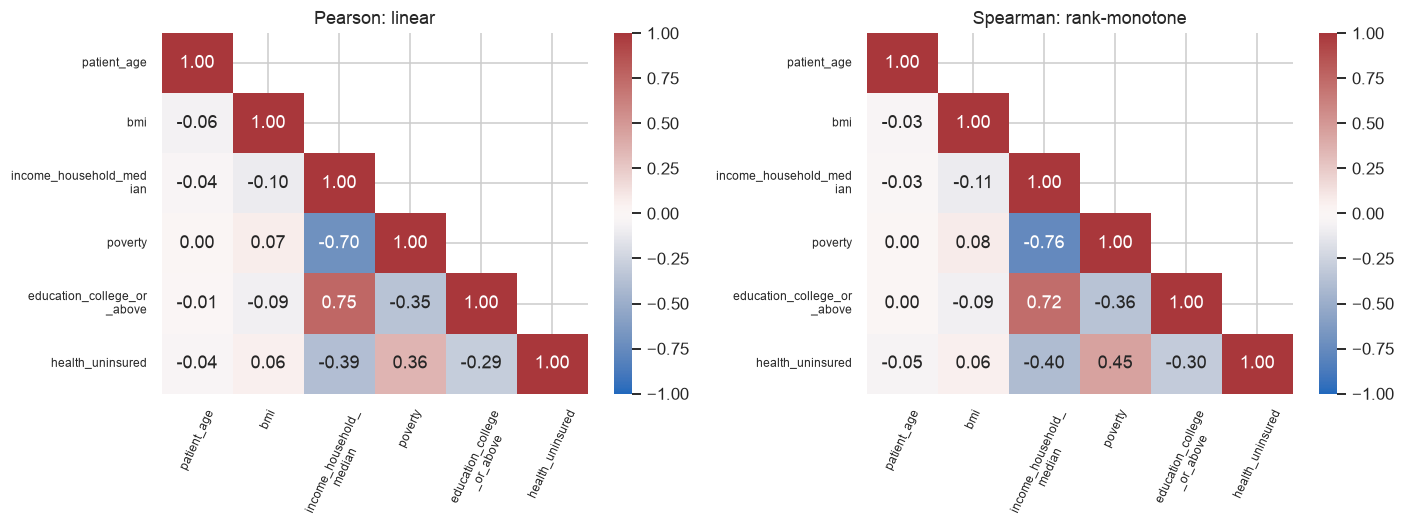

,observed_unique,dominant_observed_pct,missing_pct,constant,near_constant
feature,,,,,
patient_age,67,3.649465,0.000000,False,False
bmi,1342,2.892667,69.463815,False,False
population,738,1.851995,0.007748,False,False
density,738,1.851995,0.007748,False,False
age_median,728,1.906238,0.007748,False,False
age_under_10,718,1.851995,0.007748,False,False
age_10_to_19,725,1.851995,0.007748,False,False
age_20s,724,1.851995,0.007748,False,False
age_30s,725,1.851995,0.007748,False,False


,plot_id,feature
0,C01,patient_age
1,C02,bmi
2,C03,population
3,C04,density
4,C05,age_median
5,C06,age_under_10
6,C07,age_10_to_19
7,C08,age_20s
8,C09,age_30s
9,C10,age_40s


,patient_age,bmi,population,density,age_median,age_under_10,age_10_to_19,age_20s,age_30s,age_40s,age_50s,age_60s,age_70s,age_over_80,male,female,married,divorced,never_married,widowed,family_size,family_dual_income,income_household_median,income_household_under_5,income_household_5_to_10,income_household_10_to_15,income_household_15_to_20,income_household_20_to_25,income_household_25_to_35,income_household_35_to_50,income_household_50_to_75,income_household_75_to_100,income_household_100_to_150,income_household_150_over,income_household_six_figure,income_individual_median,home_ownership,housing_units,home_value,rent_median,rent_burden,education_less_highschool,education_highschool,education_some_college,education_bachelors,education_graduate,education_college_or_above,education_stem_degree,labor_force_participation,unemployment_rate,self_employed,farmer,race_white,race_black,race_asian,race_native,race_pacific,race_other,race_multiple,hispanic,disabled,poverty,limited_english,commute_time,health_uninsured,veteran,Ozone,PM25,N02
patient_age,1.0000,-0.0639,-0.0180,-0.0025,0.0401,-0.0265,-0.0297,-0.0206,-0.0235,-0.0258,0.0229,0.0377,0.0290,0.0460,-0.0201,0.0201,-0.0017,0.0296,-0.0087,0.0147,-0.0627,-0.0037,-0.0358,-0.0080,0.0219,0.0058,0.0260,0.0111,0.0270,0.0353,0.0369,0.0281,-0.0079,-0.0400,-0.0344,-0.0275,0.0301,-0.0095,-0.0531,-0.0502,-0.0127,-0.0619,0.0286,0.0308,-0.0031,-0.0070,-0.0052,-0.0297,-0.0053,-0.0079,-0.0283,-0.0024,0.0405,-0.0015,-0.0361,0.0041,-0.0230,-0.0539,-0.0361,-0.0479,0.0154,0.0002,-0.0282,-0.0348,-0.0363,0.0025,-0.0259,-0.0230,0.0148
bmi,-0.0639,1.0000,-0.0380,-0.0037,-0.0233,0.0565,0.0063,0.0020,-0.0058,-0.0473,-0.0424,0.0023,0.0121,0.0043,-0.0254,0.0254,-0.0356,0.0789,-0.0022,0.0717,-0.0195,-0.0708,-0.1045,0.0488,0.0740,0.0783,0.0797,0.0888,0.0944,0.0954,0.0750,0.0062,-0.0809,-0.1046,-0.1063,-0.0889,-0.0021,-0.0334,-0.0906,-0.0977,-0.0264,0.0452,0.0905,0.0112,-0.0884,-0.0753,-0.0854,-0.0904,-0.0482,-0.0070,-0.0715,0.0418,0.0103,0.0637,-0.0838,-0.0113,-0.0344,-0.0372,-0.0314,-0.0250,0.0792,0.0722,-0.0267,-0.0413,0.0619,0.0279,-0.0286,-0.0010,-0.0384
population,-0.0180,-0.0380,1.0000,0.7310,-0.5505,0.2547,0.0008,0.4371,0.6370,0.3964,-0.3731,-0.6504,-0.5401,-0.3111,-0.3058,0.3057,-0.4282,-0.3588,0.5847,-0.4860,0.4880,0.3466,0.2920,0.1815,-0.0035,-0.0491,-0.2491,-0.3042,-0.3728,-0.4224,-0.4620,-0.2967,0.1428,0.4312,0.3871,0.3149,-0.7224,0.9828,0.5595,0.6317,0.4410,0.2705,-0.6094,-0.4434,0.5145,0.4162,0.4856,0.2602,0.4246,0.2639,0.5203,-0.5322,-0.7240,0.2884,0.5920,-0.0749,0.0572,0.6196,0.4758,0.5313,-0.5332,0.1028,0.6715,0.4717,0.0579,-0.5008,0.0814,0.3855,0.6725
density,-0.0025,-0.0037,0.7310,1.0000,-0.3352,0.1056,-0.1646,0.2997,0.5226,0.2077,-0.2745,-0.4035,-0.3183,-0.1238,-0.3017,0.3017,-0.4303,-0.2851,0.5180,-0.2259,0.2624,0.1635,0.0899,0.2613,0.1605,0.1864,-0.0157,-0.0858,-0.1804,-0.2600,-0.3554,-0.3082,-0.0461,0.2192,0.1629,0.1673,-0.6939,0.7462,0.4790,0.3821,0.3354,0.2729,-0.3063,-0.5060,0.2924,0.2883,0.3024,0.0659,0.2117,0.3292,0.4358,-0.2832,-0.5604,0.3076,0.4095,-0.0513,0.0062,0.4794,0.1634,0.2749,-0.2562,0.2294,0.5862,0.5902,-0.0915,-0.4908,-0.1250,0.1994,0.5787
age_median,0.0401,-0.0233,-0.5505,-0.3352,1.0000,-0.5307,-0.4713,-0.7847,-0.6787,-0.1731,0.6865,0.8752,0.8870,0.6894,0.1235,-0.1235,0.6026,0.2241,-0.7347,0.5980,-0.4412,-0.2987,0.0152,-0.3207,-0.2376,-0.1404,0.0308,0.0721,0.1135,0.1306,0.1772,0.2247,0.0734,-0.0920,-0.0530,-0.0410,0.6644,-0.5577,-0.1279,-0.1926,-0.2139,-0.3008,0.3958,0.2913,-0.2711,-0.2302,-0.2614,-0.0978,-0.4979,-0.2650,-0.2132,0.2706,0.5768,-0.4146,-0.2540,0.0636,-0.0405,-0.3787,-0.3451,-0.3832,0.3773,-0.3487,-0.3805,0.0547,-0.2482,0.3460,-0.0535,-0.4629,-0.4871
age_under_10,-0.0265,0.0565,0.2547,0.1056,-0.5307,1.0000,0.3248,0.0323,0.2199,0.2134,-0.2372,-0.4276,-0.4935,-0.3832,-0.1300,0.1300,0.0432,-0.0453,0.0122,-0.2142,0.4295,0.1434,-0.0905,0.0079,0.0874,0.0493,0.0220,0.0077,0.0222,0.0779,0.0844,0.0773,0.0122,-0.1026,-0.0790,-0.0627,-0.1161,0.2156,-0.1884,-0.1044,-0.09

,patient_age,bmi,population,density,age_median,age_under_10,age_10_to_19,age_20s,age_30s,age_40s,age_50s,age_60s,age_70s,age_over_80,male,female,married,divorced,never_married,widowed,family_size,family_dual_income,income_household_median,income_household_under_5,income_household_5_to_10,income_household_10_to_15,income_household_15_to_20,income_household_20_to_25,income_household_25_to_35,income_household_35_to_50,income_household_50_to_75,income_household_75_to_100,income_household_100_to_150,income_household_150_over,income_household_six_figure,income_individual_median,home_ownership,housing_units,home_value,rent_median,rent_burden,education_less_highschool,education_highschool,education_some_college,education_bachelors,education_graduate,education_college_or_above,education_stem_degree,labor_force_participation,unemployment_rate,self_employed,farmer,race_white,race_black,race_asian,race_native,race_pacific,race_other,race_multiple,hispanic,disabled,poverty,limited_english,commute_time,health_uninsured,veteran,Ozone,PM25,N02
patient_age,1.0000,-0.0340,-0.0148,-0.0021,0.0310,-0.0278,-0.0322,-0.0205,-0.0208,-0.0320,0.0166,0.0351,0.0214,0.0435,-0.0137,0.0137,-0.0028,0.0291,-0.0069,0.0167,-0.0731,-0.0048,-0.0307,-0.0056,0.0254,0.0173,0.0274,0.0147,0.0271,0.0323,0.0326,0.0274,-0.0099,-0.0332,-0.0296,-0.0215,0.0311,-0.0046,-0.0414,-0.0435,-0.0084,-0.0588,0.0269,0.0323,0.0018,0.0066,0.0047,-0.0126,-0.0024,-0.0050,-0.0309,-0.0183,0.0406,-0.0056,-0.0290,-0.0139,-0.0559,-0.0572,-0.0397,-0.0498,0.0198,0.0036,-0.0358,-0.0484,-0.0477,0.0109,-0.0343,-0.0181,0.0189
bmi,-0.0340,1.0000,-0.0516,-0.0454,-0.0343,0.0618,0.0020,0.0068,-0.0075,-0.0479,-0.0522,0.0021,0.0022,-0.0206,-0.0122,0.0122,-0.0348,0.0785,-0.0071,0.0644,-0.0161,-0.0751,-0.1065,0.0613,0.0818,0.0811,0.0963,0.0976,0.0974,0.0935,0.0768,0.0064,-0.0830,-0.1052,-0.1060,-0.0929,-0.0063,-0.0479,-0.1020,-0.0926,-0.0274,0.0567,0.0905,0.0103,-0.0899,-0.0779,-0.0855,-0.0927,-0.0490,-0.0040,-0.0709,0.0429,0.0090,0.0386,-0.0796,-0.0239,-0.0305,-0.0344,-0.0309,-0.0298,0.0931,0.0794,-0.0328,-0.0472,0.0604,0.0409,-0.0238,0.0077,-0.0385
population,-0.0148,-0.0516,1.0000,0.8735,-0.6161,0.2019,0.0382,0.6179,0.7060,0.4576,-0.3900,-0.7335,-0.6561,-0.4321,-0.3594,0.3593,-0.4666,-0.3596,0.6643,-0.6210,0.5085,0.3960,0.4294,0.1867,-0.0576,-0.1530,-0.3067,-0.3631,-0.4409,-0.5122,-0.5377,-0.3096,0.1901,0.6101,0.5049,0.4295,-0.7241,0.9868,0.6552,0.7609,0.5572,0.2400,-0.7262,-0.4005,0.6256,0.5899,0.6221,0.3560,0.4749,0.2984,0.5379,-0.7313,-0.7525,0.4405,0.8212,0.2754,0.3996,0.7199,0.6462,0.6730,-0.6059,0.0435,0.7870,0.3387,0.1141,-0.5934,0.0842,0.4011,0.6836
density,-0.0021,-0.0454,0.8735,1.0000,-0.6159,0.0641,-0.0251,0.6686,0.7110,0.3793,-0.4048,-0.7285,-0.6677,-0.3635,-0.4095,0.4094,-0.5651,-0.4099,0.7685,-0.5911,0.3745,0.4414,0.4218,0.2314,-0.0118,-0.1231,-0.2889,-0.3608,-0.4663,-0.5494,-0.5913,-0.3718,0.1494,0.6171,0.5059,0.4675,-0.7814,0.8859,0.6440,0.7411,0.5613,0.1376,-0.7300,-0.5294,0.6839,0.6863,0.7055,0.3402,0.5101,0.3278,0.4852,-0.8533,-0.7390,0.4916,0.8351,0.1616,0.3115,0.6383,0.5371,0.5579,-0.6080,0.0616,0.7503,0.2697,-0.0721,-0.7091,-0.0119,0.3726,0.7907
age_median,0.0310,-0.0343,-0.6161,-0.6159,1.0000,-0.5031,-0.4008,-0.8449,-0.7486,-0.1766,0.7053,0.8926,0.9026,0.7387,0.2059,-0.2058,0.6171,0.1911,-0.7561,0.6203,-0.4481,-0.2528,-0.0200,-0.3452,-0.2407,-0.1472,-0.0087,0.0291,0.1059,0.1542,0.2349,0.2664,0.1001,-0.1753,-0.0874,-0.0900,0.7232,-0.6200,-0.1648,-0.2726,-0.3116,-0.3002,0.4309,0.2973,-0.3082,-0.2774,-0.3047,-0.1011,-0.4737,-0.3027,-0.2530,0.4404,0.6241,-0.4984,-0.4817,-0.1710,-0.2561,-0.4819,-0.4110,-0.4363,0.3494,-0.3470,-0.5263,0.0723,-0.2497,0.4866,-0.0423,-0.4617,-0.5117
age_under_10,-0.0278,0.0618,0.2019,0.0641,-0.5031,1.0000,0.4152,0.1600,0.3073,0.1811,-0.2412,-0.3814,-0.4334,-0.3998,-0.0961,0.0960,0.0533,-0.0542,0.0518,-0.1903,0.4307,0.1203,-0.0499,-0.0321,0.0242,0.0018,0.0227,0.0206,0.0254,0.0680,0.0875,0.0762,0.0334,-0.0637,-0.0499,-0.0142,-0.1093,0.1661,-0.1681,-0.0762,-0.1

,patient_age,bmi,population,density,age_median,age_under_10,age_10_to_19,age_20s,age_30s,age_40s,age_50s,age_60s,age_70s,age_over_80,male,female,married,divorced,never_married,widowed,family_size,family_dual_income,income_household_median,income_household_under_5,income_household_5_to_10,income_household_10_to_15,income_household_15_to_20,income_household_20_to_25,income_household_25_to_35,income_household_35_to_50,income_household_50_to_75,income_household_75_to_100,income_household_100_to_150,income_household_150_over,income_household_six_figure,income_individual_median,home_ownership,housing_units,home_value,rent_median,rent_burden,education_less_highschool,education_highschool,education_some_college,education_bachelors,education_graduate,education_college_or_above,education_stem_degree,labor_force_participation,unemployment_rate,self_employed,farmer,race_white,race_black,race_asian,race_native,race_pacific,race_other,race_multiple,hispanic,disabled,poverty,limited_english,commute_time,health_uninsured,veteran,Ozone,PM25,N02
patient_age,12906,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12877,12877,12877
bmi,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3941,3933,3933,3933
population,12905,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12876,12876,12876
density,12905,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12876,12876,12876
age_median,12905,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12876,12876,12876
age_under_10,12905,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12876,12876,12876
age_10_to_19,12905,3941,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12902,12905,12902,12905,12902,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12905,12905,12905,12905,12905,12905,12902,12902,12905,12905,12905,12876,12876,12876
age_20s,12905,3941,12905,12905,12905,12905,12905,12905,12905,

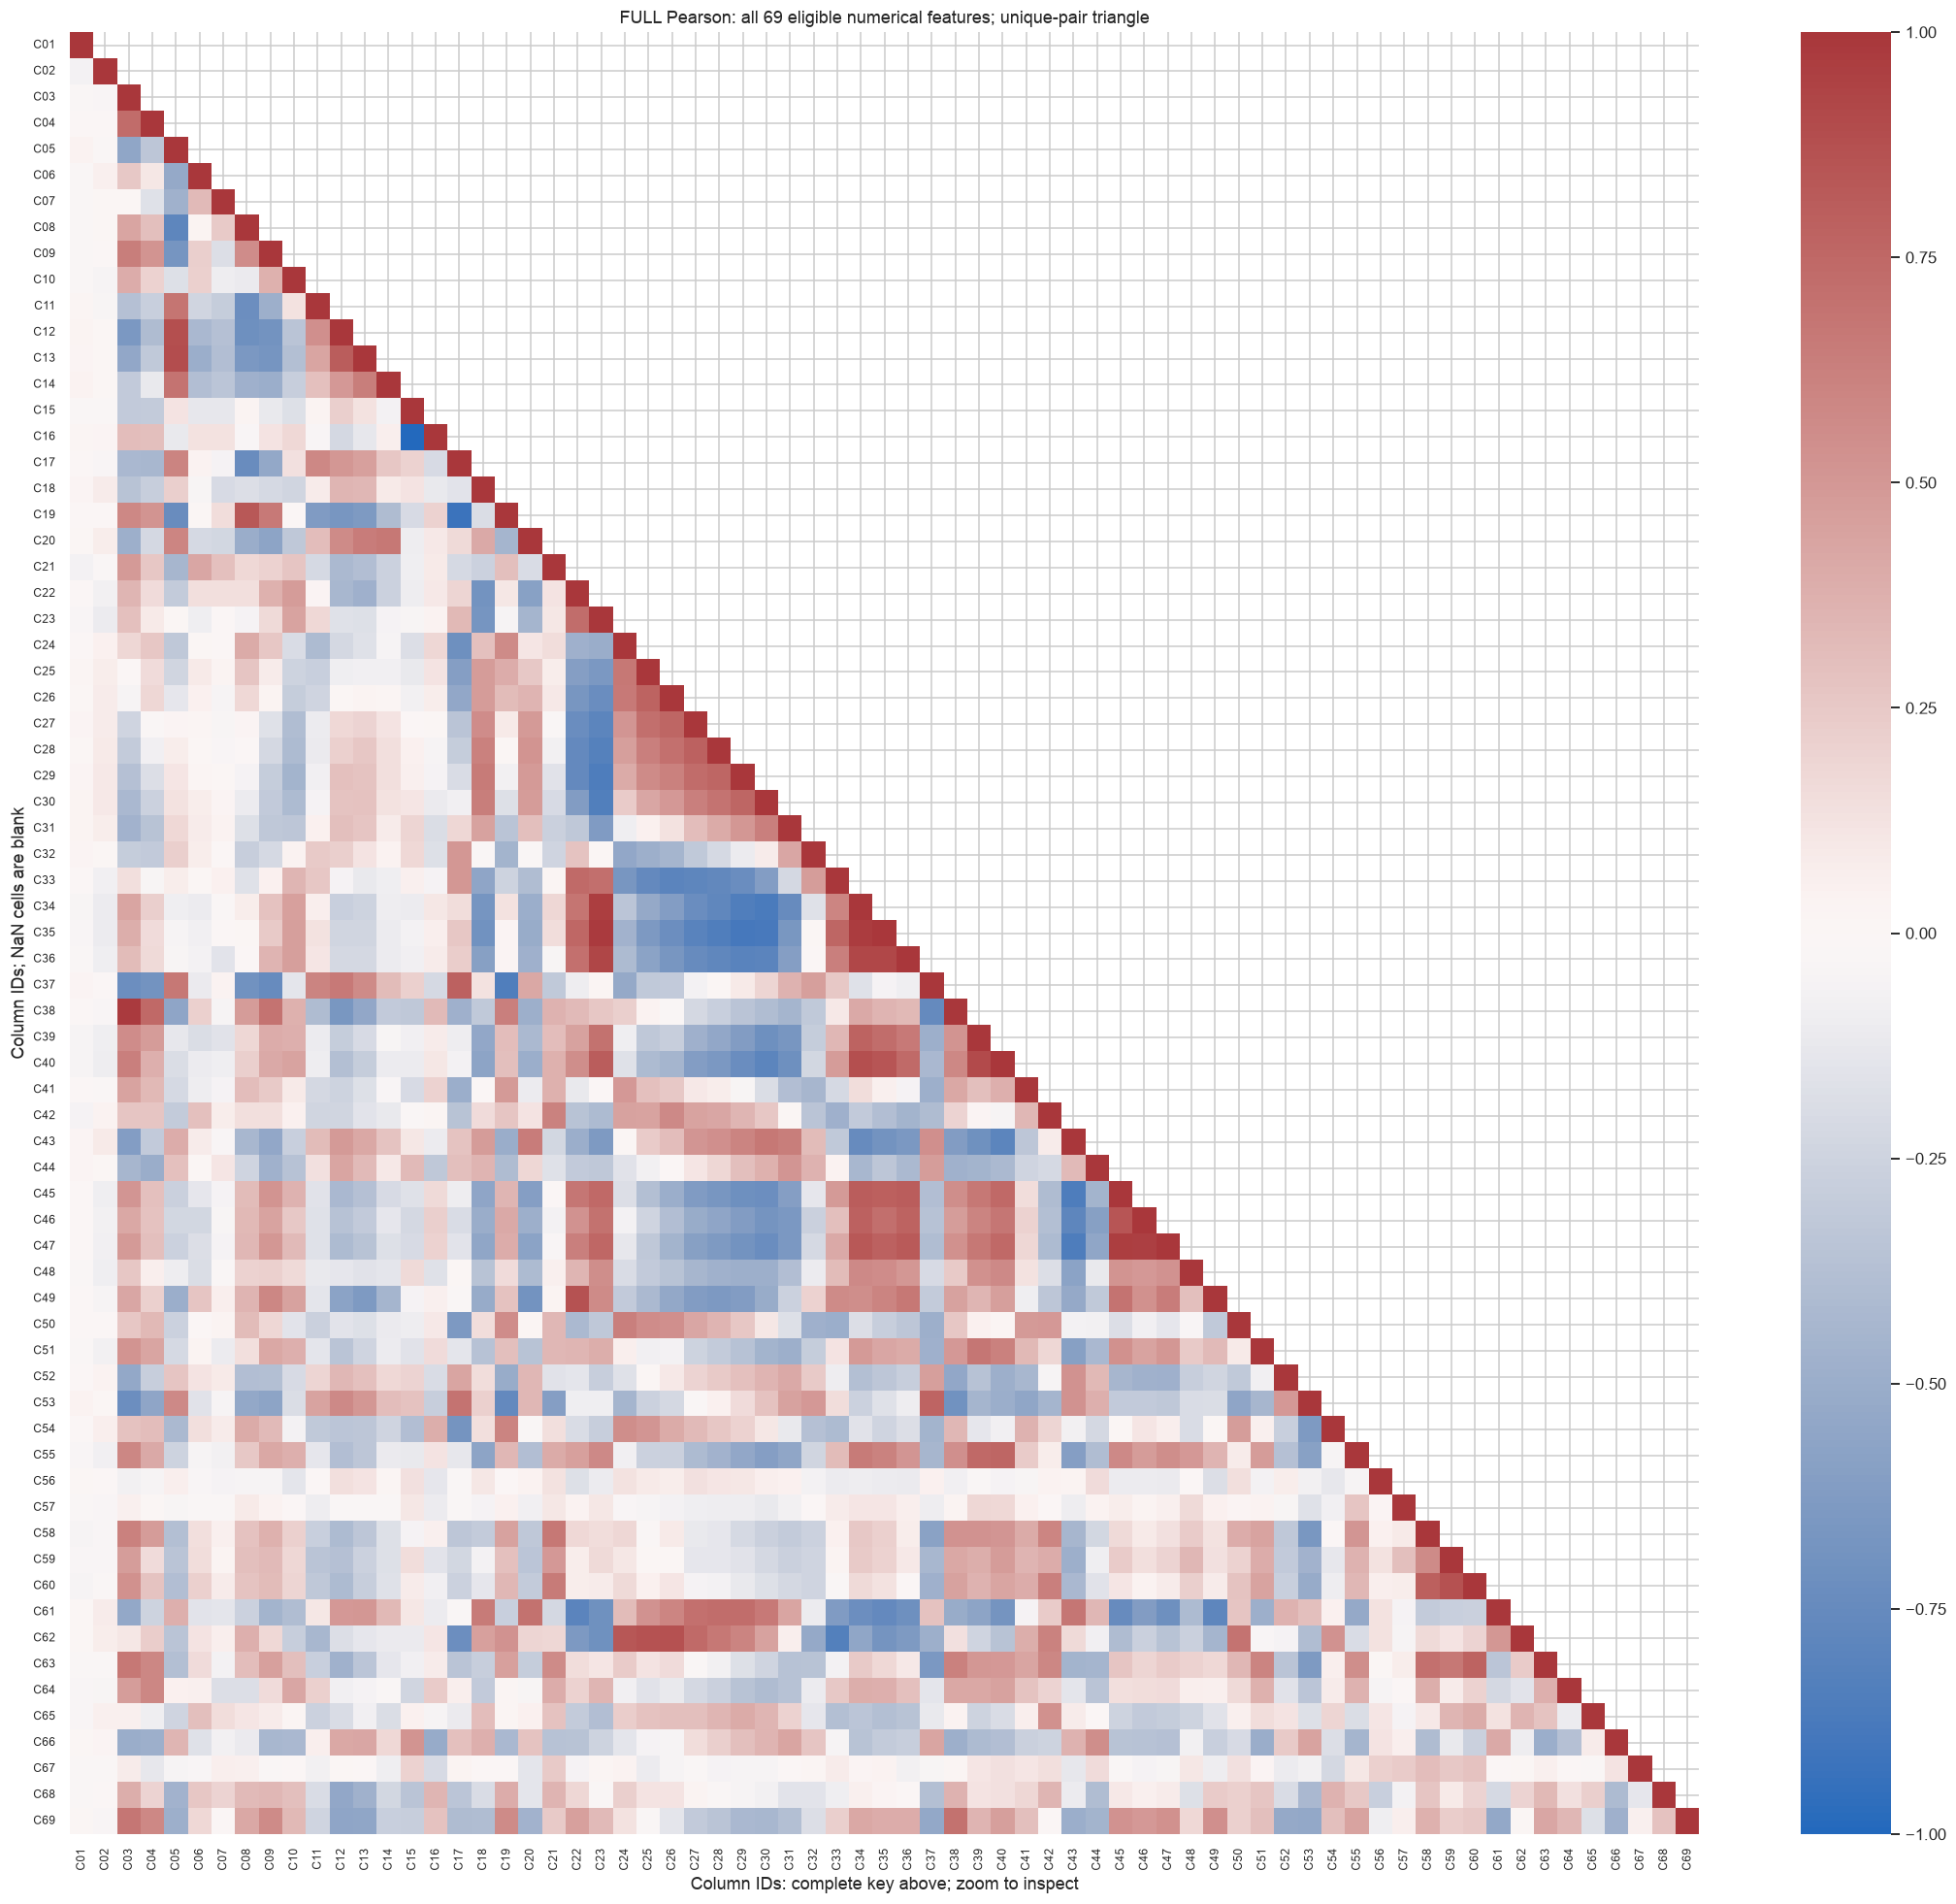

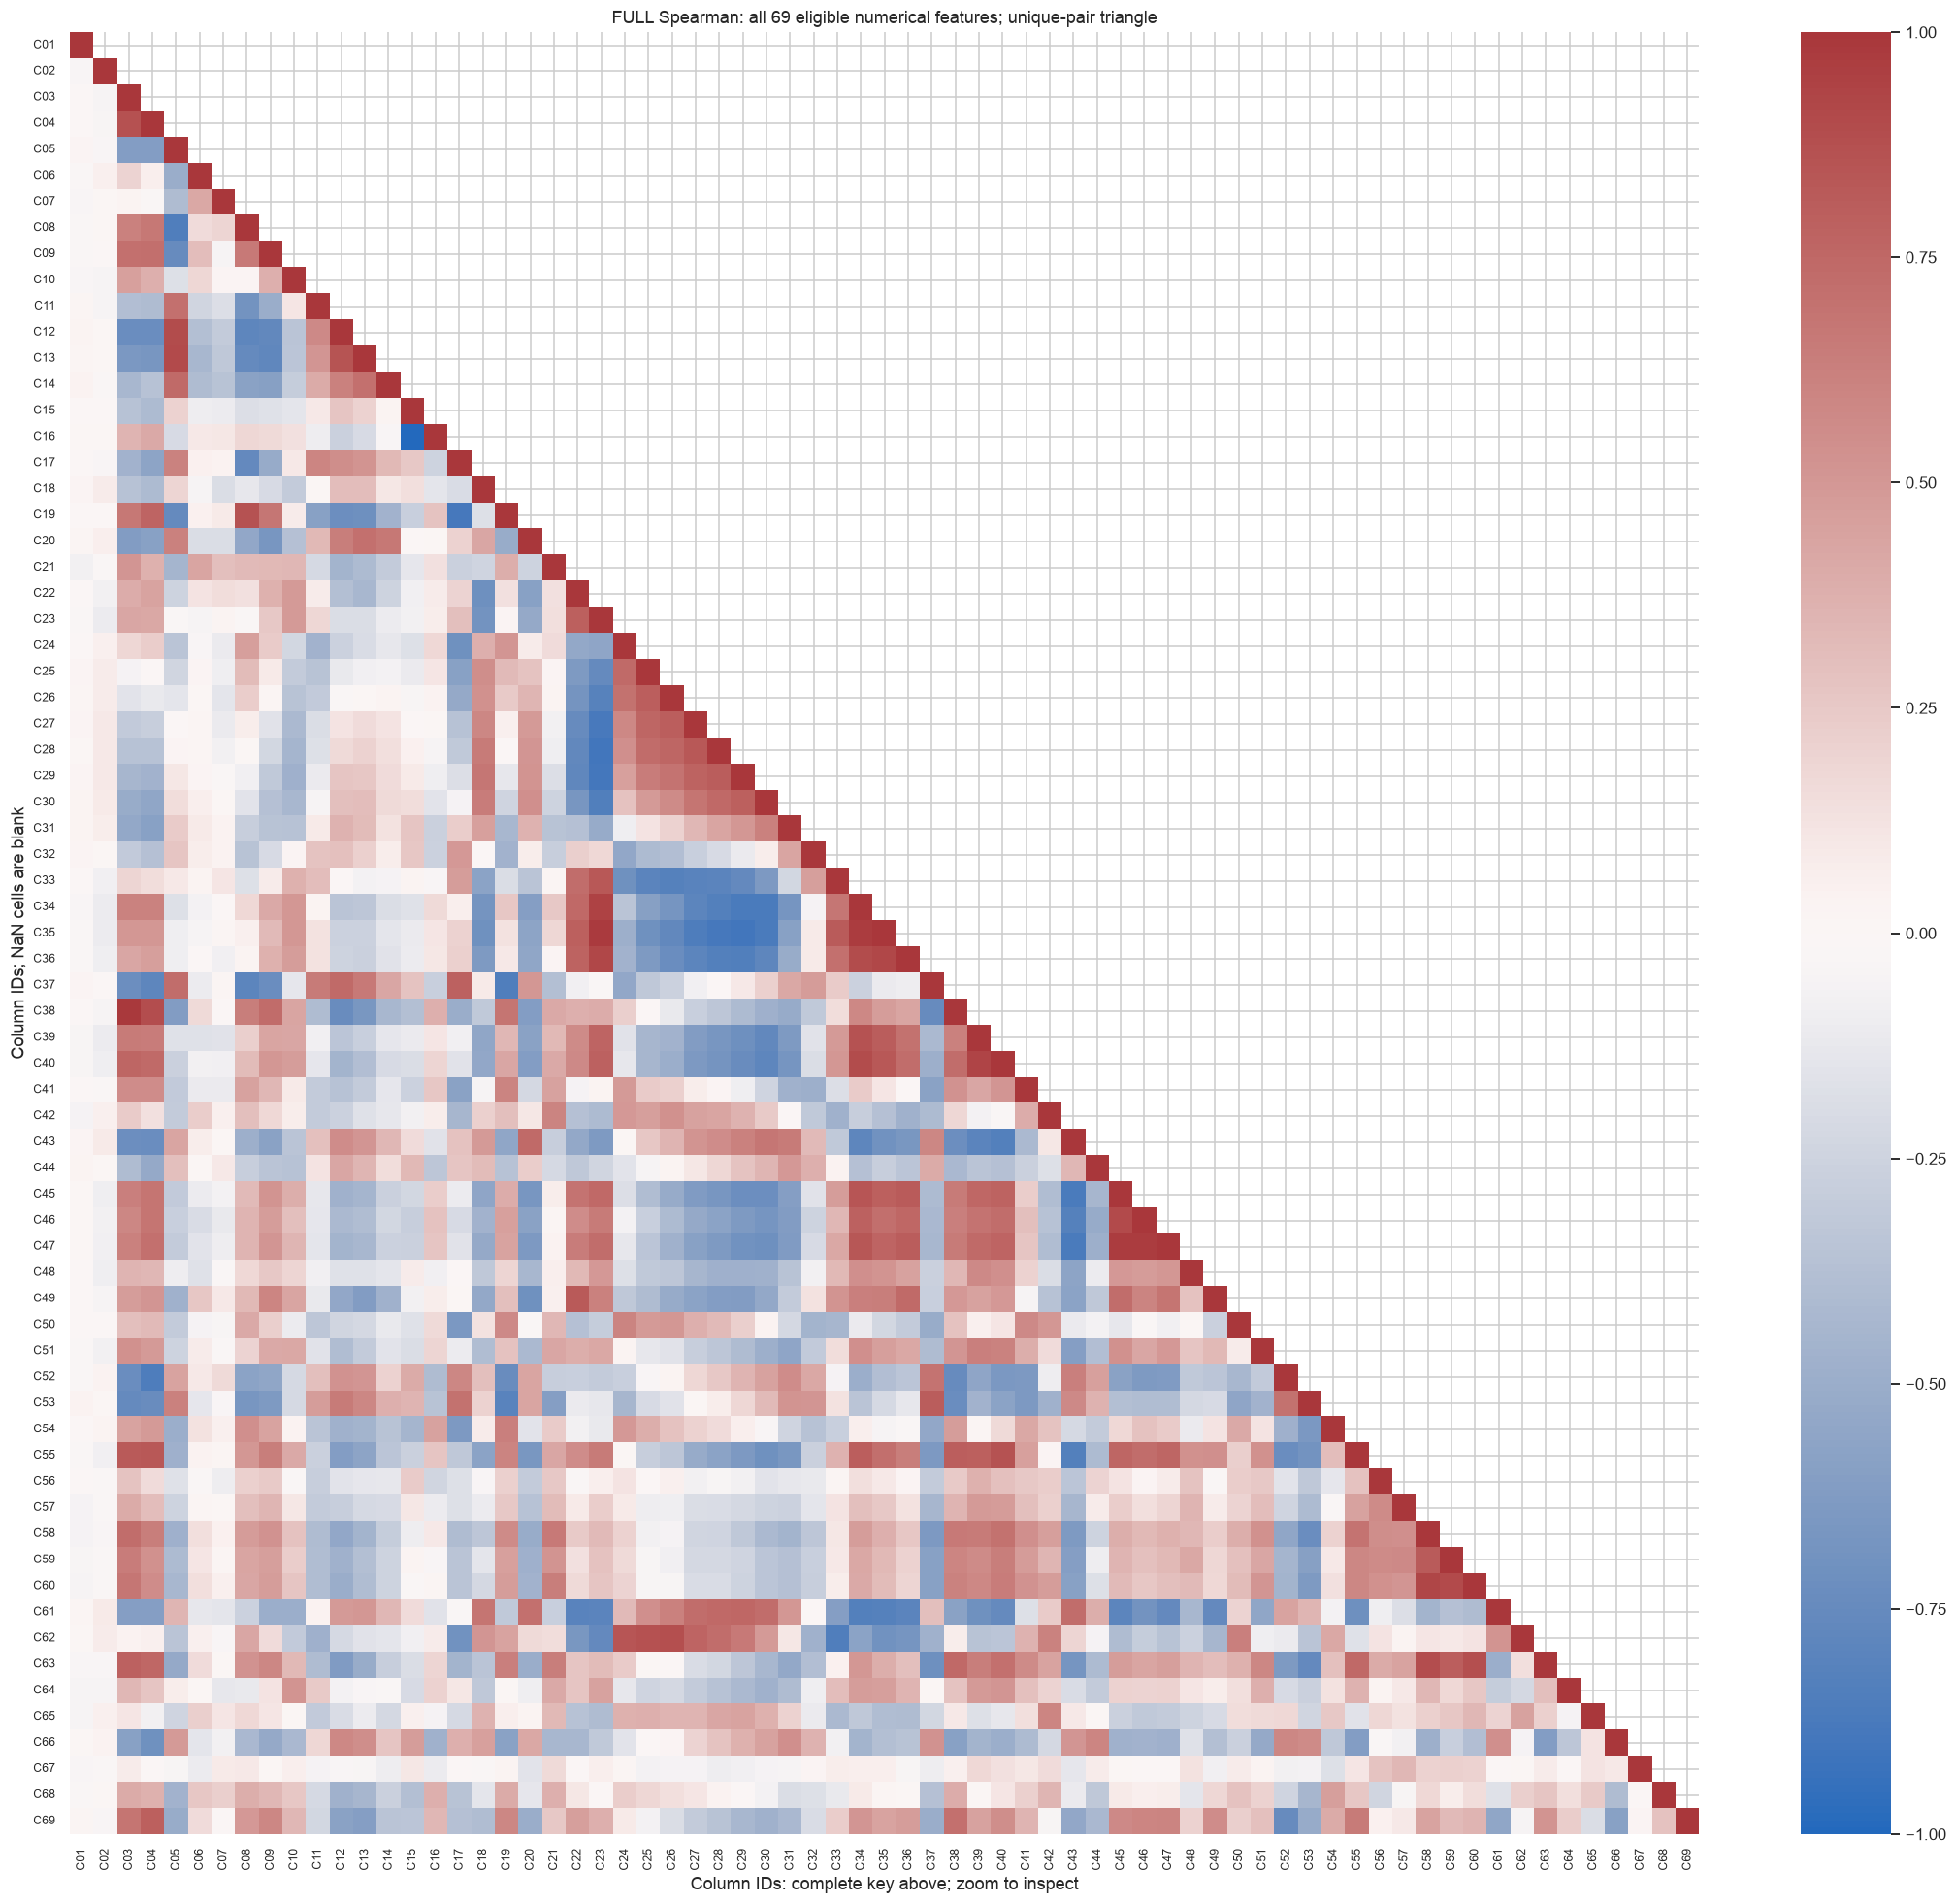

,feature_a,feature_b,pearson_r,spearman_r,paired_n,exceeds_pearson_threshold,exceeds_spearman_threshold,interpretation
169,population,housing_units,0.98285,0.98683,12905,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
273,age_median,age_70s,0.88704,0.90256,12905,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
861,male,female,-1.00000,-1.00000,12905,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
969,married,never_married,-0.92633,-0.88970,12905,True,False,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1269,income_household_median,income_household_20_to_25,-0.82186,-0.90100,12902,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1275,income_household_median,income_household_150_over,0.96608,0.93947,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1276,income_household_median,income_household_six_figure,0.97941,0.98175,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1277,income_household_median,income_individual_median,0.92813,0.91749,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1531,income_household_25_to_35,income_household_six_figure,-0.88668,-0.90290,12902,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1716,income_household_150_over,income_household_six_figure,0.97341,0.97151,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...


All unique eligible pairs: 2346
Strong Pearson pairs: 12
Strong Spearman pairs: 15
Union of strong pairs: 17
Untestable/insufficiently observed pairs: 0


,relationship,paired_n,median_abs_residual,max_abs_residual,fraction_within_1e-6,interpretation
0,male + female versus 100,12905,0.000000e+00,6.666670e-03,0.962108,not exact; a compositional explanation still n...
1,bachelors + graduate versus college_or_above,12905,3.552714e-15,1.000001e-08,1.000000,numerically redundant at tolerance 1e-6
2,income_100_to_150 + income_150_over versus six...,12902,3.552714e-15,1.000000e-08,1.000000,numerically redundant at tolerance 1e-6


Relationships numerically exact at tolerance 1e-6: 2


,ZIPs_with_multiple_observed_values,ZIPs_with_any_observed_value
population,0,738
density,0,738
income_household_median,0,737
poverty,0,737
Ozone,0,733
PM25,0,733
N02,0,733


,patients_per_ZIP
count,739.000
mean,17.464
std,24.669
min,1.000
25%,4.000
50%,9.000
75%,20.000
max,239.000


,pair,patient_weighted_spearman,equal_ZIP_spearman,paired_ZIPs
0,income_household_median / poverty,-0.7620,-0.7737,737
1,density / PM25,0.3726,0.3884,732


**Observed:** 12,906 patient records share **739 ZIP categories**, with a median of **9 patients per ZIP**. Repeated contextual values change weighting and weaken independent-observation assumptions. Later inference or evaluation should consider geographic grouping and spatial dependence.

In [12]:
correlation_focus = ["patient_age", "bmi", "income_household_median", "poverty",
                     "education_college_or_above", "health_uninsured"]
assert set(correlation_focus).issubset(continuous_columns)
pearson = df[correlation_focus].corr(method="pearson", min_periods=MIN_CORRELATION_N)
spearman = df[correlation_focus].corr(method="spearman", min_periods=MIN_CORRELATION_N)
observed_mask = df[correlation_focus].notna().astype(int)
pairwise_n = observed_mask.T @ observed_mask
print("Pairwise observed sample sizes (diagonal = observed count):")
display(pairwise_n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mask_upper = np.triu(np.ones_like(pearson, dtype=bool), k=1)
for ax, matrix, name in zip(axes, [pearson, spearman], ["Pearson: linear", "Spearman: rank-monotone"]):
    sns.heatmap(matrix, mask=mask_upper, annot=True, fmt=".2f", vmin=-1, vmax=1,
                center=0, cmap="vlag", ax=ax,
                xticklabels=[fill(c, 17) for c in correlation_focus],
                yticklabels=[fill(c, 20) for c in correlation_focus])
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=65, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.tight_layout()
plt.show()

correlation_diagnostics = audit.loc[continuous_columns, ["observed_unique", "dominant_observed_pct", "missing_pct"]].copy()
correlation_diagnostics["constant"] = correlation_diagnostics.observed_unique <= 1
correlation_diagnostics["near_constant"] = (
    (correlation_diagnostics.observed_unique > 1) &
    (correlation_diagnostics.dominant_observed_pct >= 100 * NEAR_CONSTANT_SHARE)
)
correlation_columns = [c for c in continuous_columns if not correlation_diagnostics.loc[c, "constant"]]
# Exclusion here is from a diagnostic matrix only; no raw frame columns are dropped.
all_pearson = df[correlation_columns].corr(method="pearson", min_periods=MIN_CORRELATION_N)
all_spearman = df[correlation_columns].corr(method="spearman", min_periods=MIN_CORRELATION_N)
all_observed = df[correlation_columns].notna().astype(int)
all_pairwise_n = all_observed.T @ all_observed
correlation_key = pd.DataFrame({"plot_id": [f"C{i+1:02}" for i in range(len(correlation_columns))],
                                "feature": correlation_columns})
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(correlation_diagnostics)
    display(correlation_key)
    display(all_pearson.round(4))
    display(all_spearman.round(4))
    display(all_pairwise_n)
for matrix, name in [(all_pearson, "Pearson"), (all_spearman, "Spearman")]:
    fig, ax = plt.subplots(figsize=(20, 18))
    sns.heatmap(matrix, vmin=-1, vmax=1, center=0, cmap="vlag", annot=False,
                mask=np.triu(np.ones(matrix.shape, dtype=bool), k=1),
                xticklabels=correlation_key.plot_id, yticklabels=correlation_key.plot_id, ax=ax)
    ax.tick_params(axis="both", labelsize=8)
    ax.set(title=f"FULL {name}: all {len(correlation_columns)} eligible numerical features; unique-pair triangle",
           xlabel="Column IDs: complete key above; zoom to inspect", ylabel="Column IDs; NaN cells are blank")
    plt.tight_layout()
    plt.show()

correlation_pairs = []
for i, left in enumerate(correlation_columns):
    for right in correlation_columns[i+1:]:
        r, rho = all_pearson.loc[left, right], all_spearman.loc[left, right]
        exceeds_r = bool(pd.notna(r) and abs(r) > STRONG_CORRELATION)
        exceeds_rho = bool(pd.notna(rho) and abs(rho) > STRONG_CORRELATION)
        shared_context = (left not in individual_numeric and right not in individual_numeric)
        interpretation = ("Shared contextual/compositional information is a candidate explanation; verify formulas and ZIP grain"
                          if shared_context else "Individual/contextual association; verify measurement and selection")
        correlation_pairs.append({"feature_a": left, "feature_b": right, "pearson_r": r,
                                  "spearman_r": rho, "paired_n": int(all_pairwise_n.loc[left, right]),
                                  "exceeds_pearson_threshold": exceeds_r,
                                  "exceeds_spearman_threshold": exceeds_rho,
                                  "interpretation": interpretation,
                                  "abs_spearman": abs(rho) if pd.notna(rho) else np.nan})
all_unique_pairs = pd.DataFrame(correlation_pairs)
strong_correlations = all_unique_pairs.loc[
    all_unique_pairs.exceeds_pearson_threshold | all_unique_pairs.exceeds_spearman_threshold
].copy()
# Keep the original top-Spearman teaching summary as a supplement, not as the full audit.
strong_pairs = all_unique_pairs.sort_values("abs_spearman", ascending=False).rename(columns={"spearman_r": "spearman"})
assert len(all_unique_pairs) == len(correlation_columns) * (len(correlation_columns)-1) // 2
assert not all_unique_pairs.duplicated(["feature_a", "feature_b"]).any()
assert (all_unique_pairs.feature_a != all_unique_pairs.feature_b).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", 95):
    display(strong_correlations[["feature_a", "feature_b", "pearson_r", "spearman_r", "paired_n",
                                 "exceeds_pearson_threshold", "exceeds_spearman_threshold", "interpretation"]].round(5))
print("All unique eligible pairs:", len(all_unique_pairs))
print("Strong Pearson pairs:", int(all_unique_pairs.exceeds_pearson_threshold.sum()))
print("Strong Spearman pairs:", int(all_unique_pairs.exceeds_spearman_threshold.sum()))
print("Union of strong pairs:", len(strong_correlations))
print("Untestable/insufficiently observed pairs:", int((all_unique_pairs.pearson_r.isna() | all_unique_pairs.spearman_r.isna()).sum()))

# Check plausible algebraic relationships numerically, without asserting a data dictionary.
identity_records = []
for label, parts, total in [
    ("male + female versus 100", ["male", "female"], 100.0),
    ("bachelors + graduate versus college_or_above", ["education_bachelors", "education_graduate"], "education_college_or_above"),
    ("income_100_to_150 + income_150_over versus six_figure", ["income_household_100_to_150", "income_household_150_over"], "income_household_six_figure"),
]:
    left = df[parts].sum(axis=1, min_count=len(parts))
    right = df[total] if isinstance(total, str) else pd.Series(total, index=df.index)
    valid = left.notna() & right.notna()
    residual = (left.loc[valid] - right.loc[valid]).abs()
    identity_records.append({"relationship": label, "paired_n": int(valid.sum()),
                             "median_abs_residual": residual.median(), "max_abs_residual": residual.max(),
                             "fraction_within_1e-6": (residual <= 1e-6).mean(),
                             "interpretation": "numerically redundant at tolerance 1e-6" if residual.max() <= 1e-6
                             else "not exact; a compositional explanation still needs source verification"})
algebraic_checks = pd.DataFrame(identity_records)
display(algebraic_checks)
print("Relationships numerically exact at tolerance 1e-6:", int(algebraic_checks.max_abs_residual.le(1e-6).sum()))

geo_focus = ["population", "density", "income_household_median", "poverty", "Ozone", "PM25", "N02"]
zip_variation = df.groupby("patient_zip3")[geo_focus].nunique()
geo_audit = pd.DataFrame({"ZIPs_with_multiple_observed_values": (zip_variation > 1).sum(),
                          "ZIPs_with_any_observed_value": (zip_variation > 0).sum()})
display(geo_audit)
cluster_sizes = df.groupby("patient_zip3").size()
display(cluster_sizes.describe().rename("patients_per_ZIP").to_frame().round(3))
geo_comparison_records = []
if (zip_variation <= 1).all().all():
    # first() is justified here only by the preceding observed-value consistency check.
    geo_by_zip = df.groupby("patient_zip3")[geo_focus].first()
    for left, right in [("income_household_median", "poverty"), ("density", "PM25")]:
        geo_comparison_records.append({
            "pair": f"{left} / {right}",
            "patient_weighted_spearman": df[[left, right]].corr(method="spearman").iloc[0, 1],
            "equal_ZIP_spearman": geo_by_zip[[left, right]].corr(method="spearman").iloc[0, 1],
            "paired_ZIPs": int((geo_by_zip[left].notna() & geo_by_zip[right].notna()).sum()),
        })
    display(pd.DataFrame(geo_comparison_records).round(4))
else:
    print("Within-ZIP inconsistencies found: no arbitrary first-value aggregation is used.")
display(Markdown(
    f"**Observed:** {len(df):,} patient records share **{len(cluster_sizes)} ZIP categories**, "
    f"with a median of **{cluster_sizes.median():.0f} patients per ZIP**. "
    "Repeated contextual values change weighting and weaken independent-observation assumptions. "
    "Later inference or evaluation should consider geographic grouping and spatial dependence."
))

### 7.2 A declared family of seven exploratory reference tests

The comparisons below are declared together for reporting; they are **not preregistered**.
The dataset and earlier outputs have already been inspected. They address three distinct
exploratory questions rather than serve as a preprocessing-selection rule:

1. **Two Mann–Whitney tests:** `patient_age` and `bmi` across classes 1 and 0. The two-sided
   null concerns equal underlying distributions, not simply equal medians. Observed cases are
   used separately for each feature. The asymptotic method handles ties; rank-biserial effect
   `2U1/(n1*n0) − 1` is positive when class-1 values tend to be larger. Here `U1` is returned
   with class 1 passed first. `U1/(n1*n0)` estimates `P(X1 > X0) + 0.5 P(X1 = X0)`, including ties.
   This signed effect is not a standardized mean difference or a median-shift estimate. Medians and group sizes
   accompany it. See [SciPy's Mann–Whitney reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html).
2. **Two categorical tests:** `patient_race` and `payer_type` against target, using complete
   observations for that feature. Pearson chi-square uses `correction=False`; its asymptotic
   p-value is withheld unless every observed and expected cell count is at least 5. Cramér's V
   is `sqrt(chi2 / (n * min(r-1, c-1)))`: an unsigned, uncorrected descriptive magnitude,
   not a direction or a causal effect. Passing the count rule does not verify independence. No sparse categories are
   merged. See [SciPy's contingency-test reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).
3. **Three Fisher exact tests:** missingness indicators of BMI, patient race, and payer type
   against target, using all rows. The two-sided calculation conditions on observed margins
   under an odds-ratio-one null; the reported effect is the **class-1 minus class-0 missing-rate
   difference in percentage points**, not Fisher's odds ratio. These test association, not a missing-data
   mechanism. The indicator is derived only from feature availability; it is not appended to `df`.

**Assumptions and scope:** all tests require independent observational units for their nominal
p-values. Distinct IDs alone do not verify this, and shared ZIP context is documented above.
Treat the reported p-values as **conditional reference calculations, not confirmatory evidence**.
Complete-case comparisons may be selected populations. Confounding, cohort selection, timing,
and clinical interpretation remain unresolved. Holm adjustment covers only this declared family
of seven. It can control family-wise error under dependence **between tests when their input
p-values are valid**; it cannot repair clustering of patient observations, post-EDA selection,
or the rest of this notebook's exploratory choices. Thus no reject/accept decision flag is shown. A small adjusted
p-value does not imply a useful effect, predictive value, causation, MAR, or MNAR. A nonsignificant
result does not establish equality. Floating-point p-values are shown in scientific notation.

In [13]:
numerical_test_columns = ["patient_age", "bmi"]
categorical_test_columns = ["patient_race", "payer_type"]
missingness_test_columns = ["bmi", "patient_race", "payer_type"]
test_records = []
numeric_test_records = []
for column in numerical_test_columns:
    class1 = df.loc[(df[TARGET] == 1) & df[column].notna(), column]
    class0 = df.loc[(df[TARGET] == 0) & df[column].notna(), column]
    result = stats.mannwhitneyu(class1, class0, alternative="two-sided", method="asymptotic")
    probability_superiority = result.statistic / (len(class1) * len(class0))
    delta = 2 * probability_superiority - 1
    numeric_test_records.append({"feature": column, "n_class0": len(class0), "n_class1": len(class1),
                                 "median_class0": class0.median(), "median_class1": class1.median(),
                                 "U_class1": result.statistic,
                                 "P1_greater_plus_half_ties": probability_superiority,
                                 "rank_biserial_class1_minus_class0": delta, "p_raw": result.pvalue})
    test_records.append({"test": f"MW: {column}", "p_raw": result.pvalue,
                         "effect": delta, "effect_type": "rank-biserial", "n": len(class0)+len(class1)})
numeric_tests = pd.DataFrame(numeric_test_records).set_index("feature")
display(numeric_tests.style.format({"median_class0": "{:.3f}", "median_class1": "{:.3f}",
                                   "U_class1": "{:.0f}", "P1_greater_plus_half_ties": "{:.4f}",
                                   "rank_biserial_class1_minus_class0": "{:.4f}", "p_raw": "{:.3e}"}))

,n_class0,n_class1,median_class0,median_class1,U_class1,P1_greater_plus_half_ties,rank_biserial_class1_minus_class0,p_raw
feature,,,,,,,,
patient_age,4846,8060,58.000,59.000,20917378,0.5355,0.0711,1.252e-11
bmi,1626,2315,28.275,28.150,1852842,0.4922,-0.0155,4.055e-01


**Categorical comparisons:** inspect the observed/expected count checks and complete-case sample sizes before interpreting any reference p-value.

In [14]:
categorical_test_records = []
for column in categorical_test_columns:
    available = df[column].notna()
    table = pd.crosstab(df.loc[available, column], df.loc[available, TARGET]).reindex(columns=[0, 1], fill_value=0)
    assert table.shape[0] >= 2 and (table.sum(axis=0) > 0).all()
    result = stats.chi2_contingency(table.to_numpy(), correction=False)
    expected = result.expected_freq
    count_rule_ok = bool((table.to_numpy() >= 5).all() and (expected >= 5).all())
    p_value = result.pvalue if count_rule_ok else np.nan
    cramer_v = np.sqrt(result.statistic / (table.to_numpy().sum() * min(table.shape[0]-1, table.shape[1]-1)))
    categorical_test_records.append({"feature": column, "observed_n": int(table.to_numpy().sum()),
                                     "levels": len(table), "n_class0": int(table[0].sum()), "n_class1": int(table[1].sum()),
                                     "min_observed": table.to_numpy().min(),
                                     "min_expected": expected.min(), "expected_cells_lt5": int((expected < 5).sum()),
                                     "cramers_V": cramer_v, "p_raw": p_value,
                                     "count_rule": "passed" if count_rule_ok else "p-value withheld"})
    test_records.append({"test": f"Chi-square: {column}", "p_raw": p_value,
                         "effect": cramer_v, "effect_type": "Cramer's V", "n": int(table.to_numpy().sum())})
categorical_tests = pd.DataFrame(categorical_test_records).set_index("feature")
display(categorical_tests.style.format({"min_expected": "{:.2f}", "cramers_V": "{:.4f}", "p_raw": "{:.3e}"}))

,observed_n,levels,n_class0,n_class1,min_observed,min_expected,expected_cells_lt5,cramers_V,p_raw,count_rule
feature,,,,,,,,,,
patient_race,6521,5,2326,4195,135,130.19,0,0.0382,4.916e-02,passed
payer_type,11103,3,4316,6787,895,972.59,0,0.0356,8.753e-04,passed


**Missingness comparisons:** the three 2 × 2 tables use all labeled rows and diagnose recording differences only.

In [15]:
missing_test_records = []
for column in missingness_test_columns:
    table = pd.crosstab(df[column].isna(), df[TARGET]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    assert int(table.to_numpy().sum()) == len(df)
    result = stats.fisher_exact(table.to_numpy(), alternative="two-sided")
    difference_pp = missing_by_class.loc[column, "difference_pp_class1_minus_class0"]
    missing_test_records.append({"feature": column, "n": int(table.to_numpy().sum()),
                                 "missing_n_class0": int(table.loc[True, 0]),
                                 "missing_n_class1": int(table.loc[True, 1]),
                                 "missing_pct_class0": missing_by_class.loc[column, "missing_pct_class0"],
                                 "missing_pct_class1": missing_by_class.loc[column, "missing_pct_class1"],
                                 "difference_pp": difference_pp, "p_raw": result.pvalue})
    test_records.append({"test": f"Fisher missingness: {column}", "p_raw": result.pvalue,
                         "effect": difference_pp, "effect_type": "missingness difference (pp)", "n": len(df)})
missing_tests = pd.DataFrame(missing_test_records).set_index("feature")
display(missing_tests.style.format({"missing_pct_class0": "{:.3f}", "missing_pct_class1": "{:.3f}",
                                   "difference_pp": "{:.3f}", "p_raw": "{:.3e}"}))

,n,missing_n_class0,missing_n_class1,missing_pct_class0,missing_pct_class1,difference_pp,p_raw
feature,,,,,,,
bmi,12906,3220,5745,66.447,71.278,4.831,9.207e-09
patient_race,12906,2520,3865,52.002,47.953,-4.049,8.437e-06
payer_type,12906,530,1273,10.937,15.794,4.857,6.033e-15


**Joint interpretation:** apply Holm adjustment across the declared seven-test family (not a preregistered analysis) and compare p-values with effect sizes and selection caveats.

In [16]:
family_tests = pd.DataFrame(test_records).set_index("test")
declared_family_size = len(numerical_test_columns) + len(categorical_test_columns) + len(missingness_test_columns)
assert len(family_tests) == declared_family_size
# A withheld p-value contributes 1 to retain the seven-test family size;
# its adjusted value is then hidden instead of being presented as a tested hypothesis.
testable = family_tests.p_raw.notna()
p_for_adjustment = family_tests.p_raw.where(testable, 1.0).to_numpy()
_, adjusted, _, _ = multipletests(p_for_adjustment, alpha=0.05, method="holm")
family_tests["p_holm"] = np.where(testable, adjusted, np.nan)
print(f"Holm family: {declared_family_size} declared tests; p-values remain independence-conditional references.")
display(family_tests.style.format({"p_raw": "{:.3e}", "p_holm": "{:.3e}", "effect": "{:.4f}"}))
display(Markdown(
    f"**Interpretation:** patient-age medians are **{numeric_tests.loc['patient_age', 'median_class0']:.1f}** "
    f"(class 0) and **{numeric_tests.loc['patient_age', 'median_class1']:.1f}** (class 1), with "
    f"rank-biserial effect **{numeric_tests.loc['patient_age', 'rank_biserial_class1_minus_class0']:.4f}** "
    f"and Holm reference p = **{family_tests.loc['MW: patient_age', 'p_holm']:.3e}**. "
    f"The corresponding pairwise superiority estimate, counting ties as half, is "
    f"**{numeric_tests.loc['patient_age', 'P1_greater_plus_half_ties']:.4f}**, close to the no-ordering reference 0.5. "
    f"BMI's observed-case effect is **{numeric_tests.loc['bmi', 'rank_biserial_class1_minus_class0']:.4f}** "
    f"with Holm reference p = **{family_tests.loc['MW: bmi', 'p_holm']:.3e}**. "
    "Inspect effect magnitudes and case selection alongside p-values. These comparisons neither "
    "validate feature timing nor resolve geographic dependence, confounding, or missingness mechanisms."
))

Holm family: 7 declared tests; p-values remain independence-conditional references.


,p_raw,effect,effect_type,n,p_holm
test,,,,,
MW: patient_age,1.252e-11,0.0711,rank-biserial,12906,7.515e-11
MW: bmi,4.055e-01,-0.0155,rank-biserial,3941,4.055e-01
Chi-square: patient_race,4.916e-02,0.0382,Cramer's V,6521,9.832e-02
Chi-square: payer_type,8.753e-04,0.0356,Cramer's V,11103,2.626e-03
Fisher missingness: bmi,9.207e-09,4.8314,missingness difference (pp),12906,4.603e-08
Fisher missingness: patient_race,8.437e-06,-4.0488,missingness difference (pp),12906,3.375e-05
Fisher missingness: payer_type,6.033e-15,4.8572,missingness difference (pp),12906,4.223e-14


**Interpretation:** patient-age medians are **58.0** (class 0) and **59.0** (class 1), with rank-biserial effect **0.0711** and Holm reference p = **7.515e-11**. The corresponding pairwise superiority estimate, counting ties as half, is **0.5355**, close to the no-ordering reference 0.5. BMI's observed-case effect is **-0.0155** with Holm reference p = **4.055e-01**. Inspect effect magnitudes and case selection alongside p-values. These comparisons neither validate feature timing nor resolve geographic dependence, confounding, or missingness mechanisms.

## 8. Findings, candidate methods, and unresolved decisions

The following evidence is generated from the executed diagnostics, rather than transcribed
from an external analysis. Candidate preprocessing methods are **options for later investigation**,
not implemented steps or automatic recommendations. Any later learned preprocessing must be
fit within the training folds of an appropriate validation scheme. These hypotheses were
informed by EDA of the entire labeled file; they are not independently validated conclusions.

In [17]:
strongest = strong_pairs.iloc[0]
findings = pd.DataFrame([
    {"finding": "Unequal supplied label frequencies",
     "evidence": f"class 1={balance.loc[1, 'patients']:,} ({balance.loc[1, 'share_pct']:.2f}%); class 0={balance.loc[0, 'patients']:,}",
     "implication": "Accuracy alone would have an unequal-class reference",
     "candidate preprocessing methods": "No automatic resampling; later compare justified weighting/resampling inside folds",
     "unresolved questions": "Confirm label polarity, endpoint and evaluation metric"},
    {"finding": "Substantial BMI and race missingness",
     "evidence": f"BMI missing={missing_table.loc['bmi', 'missing_pct']:.2f}%; race={missing_table.loc['patient_race', 'missing_pct']:.2f}%",
     "implication": f"BMI summaries use only {int(missing_table.loc['bmi', 'observed_n']):,}/{len(df):,} rows; imputation would be assumption-sensitive",
     "candidate preprocessing methods": "Compare justified imputation strategies and feature-only missingness indicators later",
     "unresolved questions": "Collection process and mechanism; no MCAR/MAR/MNAR conclusion"},
    {"finding": "Sparse treatment variables under temporal review",
     "evidence": f"Novel treatment observed n={missing_table.loc['metastatic_first_novel_treatment', 'observed_n']}; five clinical fields held out of association tests",
     "implication": "Too sparse for stable treatment comparisons; missing does not mean untreated",
     "candidate preprocessing methods": "Require temporal eligibility review before considering exclusion or representation",
     "unresolved questions": "Prediction time, event timestamps, source-field definitions"},
    {"finding": "Observed constants and code-description redundancy",
     "evidence": f"Single-observed-level columns={len(single_observed)}; breast code/description max mappings={code_to_description.max()}/{description_to_code.max()}",
     "implication": "Observed constancy and missingness must be distinguished",
     "candidate preprocessing methods": "Later assess fold-wise constant/redundant feature handling",
     "unresolved questions": "Do mappings and category support remain stable outside this sample?"},
    {"finding": "ZIP is categorical and creates shared context",
     "evidence": f"ZIP categories={len(cluster_sizes)}; leading-zero rows in CSV={zip_leading_zero_n}; ZIP stored as string; literal 999 count={zip_literal_999_n}, retained",
     "implication": "Numeric dtype does not define a continuous measure; context is clustered",
     "candidate preprocessing methods": "Later review categorical representations and geographically grouped validation",
     "unresolved questions": "Upstream formatting, geographic validity/coverage and deployment population; different ZIPs need not be independent"},
    {"finding": "Right tails and empirical extreme-value flags",
     "evidence": f"Density skew={numerical_summary.loc['density', 'sample_skewness']:.2f}; BMI Tukey flags={int(outlier_review.loc['bmi', 'flagged_n'])}/{int(outlier_review.loc['bmi', 'observed_n'])}",
     "implication": "Marginal extremes warrant verification, not deletion",
     "candidate preprocessing methods": "Later compare robust methods or transformations only if domain-justified",
     "unresolved questions": "Units, source errors, clinically plausible ranges, geographic weighting"},
    {"finding": "High categorical cardinality / sparse levels",
     "evidence": f"ZIP <1% flags {int(zip_support.loc['share < 1%', 'flagged_levels'])} levels / {zip_support.loc['share < 1%', 'patients_pct']:.2f}% of patients; count <5 covers {zip_support.loc['count < 5', 'patients_pct']:.2f}%",
     "implication": "The 1% rule is blunt for ZIP; support and unknown-level behavior matter",
     "candidate preprocessing methods": "Compare count-based support diagnostics and unknown-level handling; any justified grouping/encoding must be fold-local",
     "unresolved questions": "Which level groupings are permitted and semantically defensible?"},
    {"finding": "Numerical redundancy among candidate features",
     "evidence": f"Largest |Spearman|: {strongest.feature_a}/{strongest.feature_b}, rho={strongest.spearman:.4f}, paired n={strongest.paired_n}",
     "implication": "Compositional relations and repeated area values may explain overlap",
     "candidate preprocessing methods": "Later review redundant groups; no feature selection performed",
     "unresolved questions": "Variable definitions, algebraic dependencies, geographic grain"},
    {"finding": "Small age rank effect despite a small reference p-value",
     "evidence": f"Age rank-biserial={numeric_tests.loc['patient_age', 'rank_biserial_class1_minus_class0']:.4f}; Holm reference p={family_tests.loc['MW: patient_age', 'p_holm']:.3e}; {len(family_tests)} declared tests",
     "implication": "Sample size and selection matter; nominal significance is not practical value",
     "candidate preprocessing methods": "No method chosen from a p-value; preserve hypotheses for later validation",
     "unresolved questions": "Independence, geographic clustering, confounding and temporal availability"},
    {"finding": "All labeled rows have already informed EDA",
     "evidence": f"All {len(df):,} rows contribute to descriptive or label-based diagnostics; no split was created",
     "implication": "A later internal holdout cannot be called completely untouched",
     "candidate preprocessing methods": "Freeze candidate plans; fit every learned preprocessing step only within development folds",
     "unresolved questions": "Known-ZIP versus new-ZIP deployment; internal assessment remains post-EDA; independent external assessment needed"},
    {"finding": "Required normality-reference audit",
     "evidence": f"All {len(normality_table)} numerical candidates: reject={normality_counts['reject H0']}, fail-to-reject={normality_counts['fail to reject H0']}, not-testable={normality_counts['NOT TESTABLE']}",
     "implication": "A marginal rejection is not an effect size or a scaler-selection rule",
     "candidate preprocessing methods": "Compare required Min-Max, Z-score, Robust and both Quantile outputs inside folds",
     "unresolved questions": "iid calibration, bounded/shared contextual variables, model-specific usefulness"},
    {"finding": "Full numerical correlation coverage",
     "evidence": f"{len(correlation_columns)} features; {len(all_unique_pairs)} unique pairs; {len(strong_correlations)} pairs exceed either strict 0.9 threshold",
     "implication": "Possible shared/compositional information; pairwise association does not diagnose all multicollinearity",
     "candidate preprocessing methods": "Later verify formulas, inspect design rank/VIF, compare representatives, regularization or PCA",
     "unresolved questions": "No raw feature dropped; exact dependencies require dictionary confirmation"},
    {"finding": "Limited-scope Little reference does not establish a mechanism",
     "evidence": f"age/BMI: statistic={little_report['test_statistic']:.6f}, df={little_report['degrees_of_freedom']}, p={little_report['p_value']:.6g}; formal decision={little_report['decision']}",
     "implication": "No global MCAR/MAR/MNAR label is justified",
     "candidate preprocessing methods": "Use transparent missingness assumptions and sensitivity experiments; never infer MAR/MNAR from rejection",
     "unresolved questions": f"Gaussian/reference calibration and dependence unresolved; scope excludes {len(feature_columns)-len(little_included)} candidate features"},
]).rename(columns={
    "finding": "Finding", "evidence": "Evidence", "implication": "Implication",
    "candidate preprocessing methods": "Candidate preprocessing methods",
    "unresolved questions": "Limitations / Questions",
})
display(findings.style.hide(axis="index").set_properties(**{
    "text-align": "left", "vertical-align": "top", "white-space": "normal", "max-width": "18em"
}))

Finding,Evidence,Implication,Candidate preprocessing methods,Limitations / Questions
Unequal supplied label frequencies,"class 1=8,060 (62.45%); class 0=4,846",Accuracy alone would have an unequal-class reference,No automatic resampling; later compare justified weighting/resampling inside folds,"Confirm label polarity, endpoint and evaluation metric"
Substantial BMI and race missingness,BMI missing=69.46%; race=49.47%,"BMI summaries use only 3,941/12,906 rows; imputation would be assumption-sensitive",Compare justified imputation strategies and feature-only missingness indicators later,Collection process and mechanism; no MCAR/MAR/MNAR conclusion
Sparse treatment variables under temporal review,Novel treatment observed n=24; five clinical fields held out of association tests,Too sparse for stable treatment comparisons; missing does not mean untreated,Require temporal eligibility review before considering exclusion or representation,"Prediction time, event timestamps, source-field definitions"
Observed constants and code-description redundancy,Single-observed-level columns=2; breast code/description max mappings=1/1,Observed constancy and missingness must be distinguished,Later assess fold-wise constant/redundant feature handling,Do mappings and category support remain stable outside this sample?
ZIP is categorical and creates shared context,"ZIP categories=739; leading-zero rows in CSV=0; ZIP stored as string; literal 999 count=1, retained",Numeric dtype does not define a continuous measure; context is clustered,Later review categorical representations and geographically grouped validation,"Upstream formatting, geographic validity/coverage and deployment population; different ZIPs need not be independent"
Right tails and empirical extreme-value flags,Density skew=4.04; BMI Tukey flags=2/3941,"Marginal extremes warrant verification, not deletion",Later compare robust methods or transformations only if domain-justified,"Units, source errors, clinically plausible ranges, geographic weighting"
High categorical cardinality / sparse levels,ZIP <1% flags 733 levels / 92.14% of patients; count <5 covers 3.64%,The 1% rule is blunt for ZIP; support and unknown-level behavior matter,Compare count-based support diagnostics and unknown-level handling; any justified grouping/encoding must be fold-local,Which level groupings are permitted and semantically defensible?
Numerical redundancy among candidate features,"Largest |Spearman|: male/female, rho=-1.0000, paired n=12905",Compositional relations and repeated area values may explain overlap,Later review redundant groups; no feature selection performed,"Variable definitions, algebraic dependencies, geographic grain"
Small age rank effect despite a small reference p-value,Age rank-biserial=0.0711; Holm reference p=7.515e-11; 7 declared tests,Sample size and selection matter; nominal significance is not practical value,No method chosen from a p-value; preserve hypotheses for later validation,"Independence, geographic clustering, confounding and temporal availability"
All labeled rows have already informed EDA,"All 12,906 rows contribute to descriptive or label-based diagnostics; no split was created",A later internal holdout cannot be called completely untouched,Freeze candidate plans; fit every learned preprocessing step only within development folds,Known-ZIP versus new-ZIP deployment; internal assessment remains post-EDA; independent external assessment needed


### EDA conclusion

The main issues are extensive BMI/race missingness, almost unrecorded treatment fields with
unverified timing, repeated geographic context, overlapping contextual variables, and right-tailed
numerical distributions. Candidate experiments should start with simple, fold-fitted imputation
baselines with feature-only missingness indicators, then compare robust handling or transformations
only where justified. Category support and unknown-level handling deserve separate attention;
blindly pooling every ZIP below 1% would erase most distinctions. Neither p-values nor Tukey flags
select a method. An authoritative dictionary and instructor clarification of ambiguous rubric items are needed
before deciding clinical eligibility, units, code meanings, or permitted experiment details. Subsequent experiments must control
selection from this whole-file EDA, temporal leakage, fold leakage, missing-case selection, and
geographic dependence. No preprocessing method or model has been fitted in this notebook.

### Validation plan — proposed, not executed

**Full-data EDA is not training-only method selection.** All rows and labels in this file have
already been examined. A split created now can be reserved against *further* fitting/tuning,
but cannot retroactively become a completely untouched test set. Report this exposure whenever
presenting later internal results; new independent assessment data would be needed for a fresh
external check. The official unlabeled competition test file is not used here or treated as
available labeled ground truth.

1. **Confirm the deployment question first.** For generalization to new ZIP areas, keep each
   `patient_zip3` group entirely within one partition. For future patients in already represented
   ZIPs, a patient-level stratified split answers a different question and may exploit shared
   context; report a ZIP-disjoint sensitivity assessment rather than treating these estimands
   as interchangeable. Distinct IDs do not prove distinct people; adjacent ZIPs can remain dependent.
2. **Freeze the plan before the next experiments.** A proposed new-ZIP design is a development /
   internal-assessment split using `GroupShuffleSplit(test_size=0.20, random_state=42)` on ZIP.
   Here 20% refers to **groups, not patients**; check row counts and label support in both parts.
   Do not search seeds for favorable performance. Mark the reserved part **post-EDA internal
   assessment**, keep it out of later tuning, and disclose its prior EDA exposure.
3. **Compare candidates inside development data only.** Proposed five-fold
   `StratifiedGroupKFold(shuffle=True, random_state=42)` keeps ZIPs disjoint while attempting class
   balance, which is not guaranteed. Verify non-overlap of IDs/ZIPs, both-class support, and fold
   sizes. Learn imputation, scaling, rarity thresholds, category maps, feature selection, and any
   resampling only on the training portion of each fold; apply the fitted rules to that fold's
   validation portion. Do not compute those rules from the full CSV. Predeclare metrics and
   comparisons, and report their variability; broader tuning may require nested grouped CV.
4. **Interpret the eventual assessment honestly.** After method choices are fixed, a single
   evaluation on the reserved portion limits further tuning leakage but does not undo EDA
   selection. Keep geographic grouping and unknown-category behavior consistent with deployment.
   Confirm the design and course constraints with the supervisor before executing it.

These are proposed protocol choices, not a performed split or a guarantee of independence.
See the [scikit-learn grouped-validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).

### Decisions requiring confirmation before the next stage

- Authoritative dictionary: target polarity, units, disease-code systems, eligibility, contextual
  reference periods, baseline prediction time, and when each candidate feature is recorded.
- Rubric ambiguities recorded in `RUBRIC_AUDIT.md`; whether future evaluation targets known or unseen ZIPs.
- A frozen validation/assessment protocol that explicitly discloses the full-file EDA exposure.

No imputation, encoding, scaling, row/feature deletion, outlier treatment, SMOTE, or training
notebook is introduced in this stage.

### Reproduce and publish without private CSV access in CI

Run this notebook with the project's `.venv` kernel from the root or `book/tabular/`, using
**Restart Kernel → Run All**. Root discovery uses `myst.yml` and the existing validator. For another
dataset, adapt the configuration and review the explicit semantic, plot, and test-column lists;
do not infer scientific roles from numeric dtype alone. Executing EDA needs local training data.

The `.ipynb` stores aggregate tables, figures, and interpretation after successful local execution.
The Pages workflow uses `jupyter book build --html` **without `--execute`**, rendering saved outputs
without loading the CSV or needing the local kernel. See [MyST execution documentation](https://mystmd.org/guide/execute-notebooks).
Keep executed outputs for publication, or rerun locally after clearing them. No patient rows or
IDs are displayed. The final checksum/fingerprint cell verifies raw-file and frame preservation.
Committing and publishing remain separate owner decisions.

### Rubric gate before preprocessing

Required numerical distribution, correlation and missingno calculations are now explicit. The
Little calculation can succeed numerically while a calibrated missingness-mechanism verdict
remains BLOCKED. Do not claim full EDA compliance from execution alone. The official project also
requires part (b), a separate image-or-text pipeline, and complete preprocessing/evaluation work.
See `RUBRIC_AUDIT.md` for exact method grids, masking rates, metrics, optional wording and grading
conflicts. They are future requirements, not experiments performed by this notebook.


In [18]:
raw_sha256_after = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
frame_fingerprint_after = hashlib.sha256(
    pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()
).hexdigest()
assert raw_sha256_after == raw_sha256_before, "Raw CSV changed during this notebook execution"
assert frame_fingerprint_after == frame_fingerprint_before, "Loaded training frame was mutated"
assert df.dtypes.equals(dtypes_before) and df.shape == shape_before
assert isinstance(df.patient_zip3.dtype, pd.StringDtype)
assert df.patient_zip3.equals(zip_tokens)
assert len(audit) == len(feature_columns) and len(family_tests) == declared_family_size
print("PASS: raw CSV SHA-256 unchanged; loaded frame values, index, dtypes and shape unchanged.")
print(f"PASS: {len(audit)} features audited; ZIP strings preserved and excluded from continuous analyses; "
      f"{len(family_tests)} independence-conditional reference tests reported.")
print("Read-only EDA execution finished. No transformed dataset, patient-row export, preprocessing fit, or model was produced.")
assert len(normality_table) == len(continuous_columns)
assert all_pearson.shape == all_spearman.shape == all_pairwise_n.shape
assert len(all_unique_pairs) == len(correlation_columns)*(len(correlation_columns)-1)//2
print("Required EDA calculations executed; Little calibration status:", little_report["decision"])


PASS: raw CSV SHA-256 unchanged; loaded frame values, index, dtypes and shape unchanged.
PASS: 81 features audited; ZIP strings preserved and excluded from continuous analyses; 7 independence-conditional reference tests reported.
Read-only EDA execution finished. No transformed dataset, patient-row export, preprocessing fit, or model was produced.
Required EDA calculations executed; Little calibration status: BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported
